# ArchR pipeline

This notebook contains QC, processing and plotting of snATACseq data. Input files are two arrow files that were created using the create_arrow_files_archR.ipynb notebook.

# Basic processing

Imports arrow files, creates a project, performs basic QC, calls peaks & does some preliminary clustering.

In [1]:
version

               _                           
platform       aarch64-apple-darwin20      
arch           aarch64                     
os             darwin20                    
system         aarch64, darwin20           
status                                     
major          4                           
minor          5.0                         
year           2025                        
month          04                          
day            11                          
svn rev        88135                       
language       R                           
version.string R version 4.5.0 (2025-04-11)
nickname       How About a Twenty-Six      

In [2]:
renv::init()
renv::activate()
renv::status()

- Using Bioconductor version '3.21'.
A large number of files (1005 in total) have been discovered.
It may take renv a long time to scan these files for dependencies.
Consider using .renvignore to ignore irrelevant files.
See `?renv::dependencies` for more information.
Set `options(renv.config.dependencies.limit = Inf)` to disable this warning.

- The project is out-of-sync -- use `renv::status()` for details.
A large number of files (1005 in total) have been discovered.
It may take renv a long time to scan these files for dependencies.
Consider using .renvignore to ignore irrelevant files.
See `?renv::dependencies` for more information.
Set `options(renv.config.dependencies.limit = Inf)` to disable this warning.

The following package(s) are in an inconsistent state:

 package                            installed recorded used
 AnnotationDbi                      y         n        y   
 ArchR                              y         n        y   
 base64enc                          y    

In [3]:
library(ArchR)
library(ggrepel)
library(pheatmap)
library(patchwork)
library(svglite)
library(gridExtra)
library(viridis)
library(svglite)


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,--,__,=##,__   ///
        ,    __==    ___,-,__,--'#'  ==='      `-'    | ##,-/
        -,____,---'       \\####\\________________,--\\_##,/
           ___      .______        ______  __    __  .______      
          /   \     |   _ 

Set genome to mm10.

In [4]:
addArchRGenome("mm10")
addArchRThreads(threads = 16)

Setting default genome to Mm10.

Input threads is equal to or greater than ncores minus 1 (7)
Setting cores to ncores minus 2. Set force = TRUE to set above this number!

Setting default number of Parallel threads to 6.



Import Arrow files (created using create_arrow_files_archR.ipynb)

In [5]:
ArrowFiles <- c("HFD.arrow", "LFD.arrow")

# Create project file
proj <- ArchRProject(
  ArrowFiles = ArrowFiles,
  outputDirectory = "~/Desktop/ArchR",
  copyArrows = FALSE
)

Using GeneAnnotation set by addArchRGenome(Mm10)!

Using GeneAnnotation set by addArchRGenome(Mm10)!

Validating Arrows...

Getting SampleNames...



Getting Cell Metadata...



Merging Cell Metadata...

Initializing ArchRProject...


                                                   / |
                                                 /    \
            .                                  /      |.
            \\\                              /        |.
              \\\                          /           `|.
                \\\                      /              |.
                  \                    /                |\
                  \\#####\           /                  ||
                ==###########>      /                   ||
                 \\##==......\    /                     ||
            ______ =       =|__ /__                     ||      \\\
        ,--' ,----`-,__ ___/'  --,-`-===================##========>
       \               '        ##_______ _____ ,-

# QC

Plot TSS, fragment size distribution and fragments per cell

1 


Picking joint bandwidth of 0.0629

ArchR logging to : ArchRLogs/ArchR-plotFragmentSizes-75f649331c50-Date-2026-01-13_Time-05-47-38.46438.log
If there is an issue, please report to github with logFile!

ArchR logging successful to : ArchRLogs/ArchR-plotFragmentSizes-75f649331c50-Date-2026-01-13_Time-05-47-38.46438.log



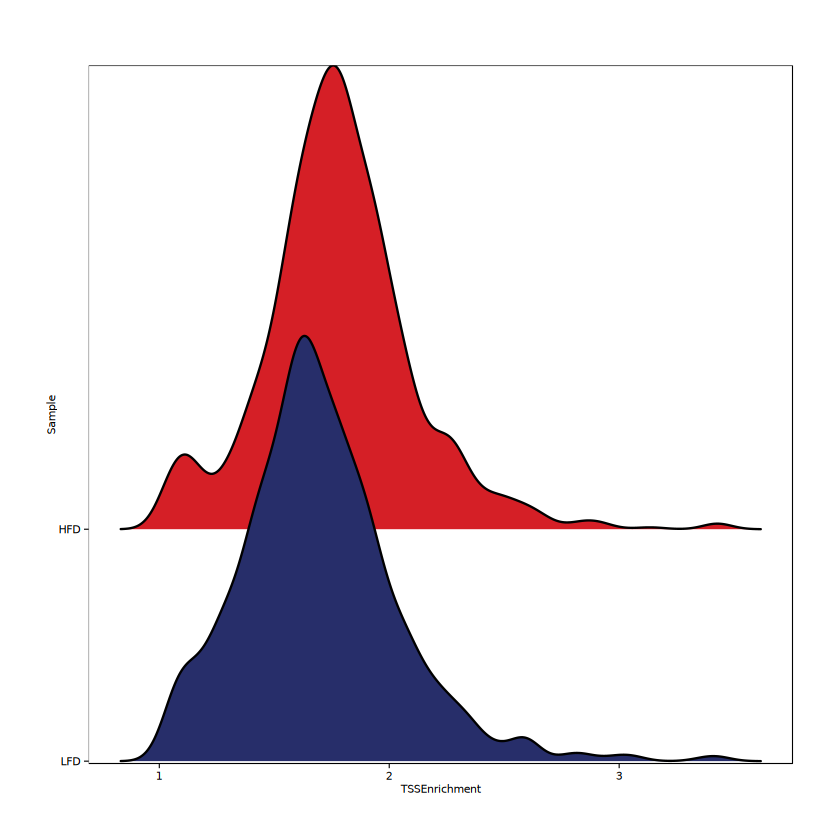

1 


Picking joint bandwidth of 2650



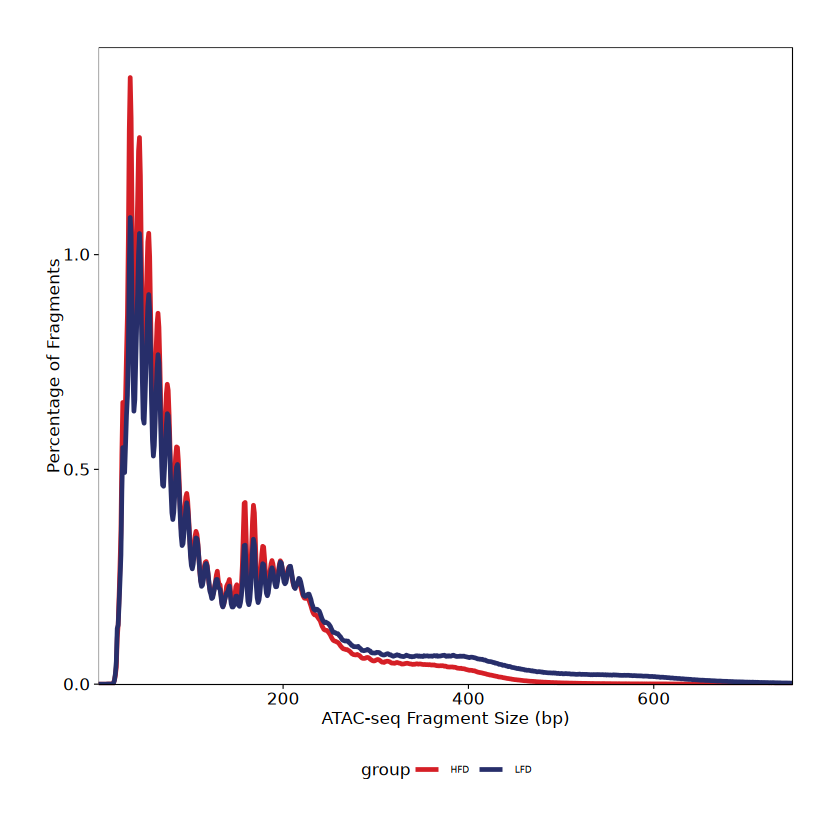

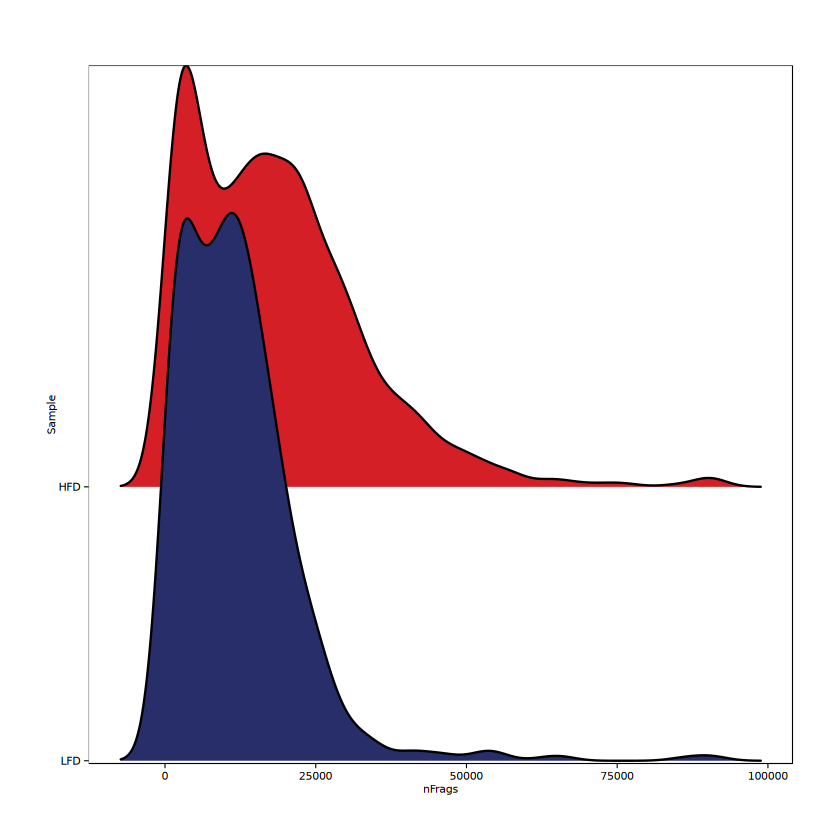

In [6]:
# TSS enrichment
p1 <- plotGroups(ArchRProj = proj, groupBy = "Sample", colorBy = "cellColData", name = "TSSEnrichment")
p1

# Fragment size distribution
p2 <- plotFragmentSizes(ArchRProj = proj)
p2

# Number of fragments per cell
p3 <- plotGroups(ArchRProj = proj, groupBy = "Sample", colorBy = "cellColData", name = "nFrags")
p3

# Peak Calling

Inbuilt ArchR function for peak calling.

In [7]:
proj <- addGroupCoverages(
  ArchRProj = proj,
  groupBy = "Sample", 
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addGroupCoverages-75f62ff15834-Date-2026-01-13_Time-05-48-01.924783.log
If there is an issue, please report to github with logFile!

Skipping validation of empty chromosomes since `force` = TRUE!

HFD (1 of 2) : CellGroups N = 2

LFD (2 of 2) : CellGroups N = 2

2026-01-13 05:48:02.275559 : Creating Coverage Files!, 0.006 mins elapsed.

2026-01-13 05:48:02.277991 : Batch Execution w/ safelapply!, 0.006 mins elapsed.

2026-01-13 05:48:02.28019 : Group HFD._.Rep1 (1 of 4) : Creating Group Coverage File : HFD._.Rep1.insertions.coverage.h5, 0.006 mins elapsed.

Number of Cells = 500

Coverage File Exists!

Added Coverage Group

Added Metadata Group

Added ArrowCoverage Class

Added Coverage/Info

Added Coverage/Info/CellNames

2026-01-13 05:48:18.421532 : Group HFD._.Rep2 (2 of 4) : Creating Group Coverage File : HFD._.Rep2.insertions.coverage.h5, 0.275 mins elapsed.

Number of Cells = 40

Coverage File Exists!

Added Coverage Group

Added Metadata Group


R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call
R_zmq_msg_send errno: 4 strerror: Interrupted system call


Completed Kmer Bias Calculation

Adding Kmer Bias (1 of 4)

Adding Kmer Bias (2 of 4)

Adding Kmer Bias (3 of 4)

Adding Kmer Bias (4 of 4)

2026-01-13 05:49:13.235784 : Finished Creation of Coverage Files!, 1.189 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-addGroupCoverages-75f62ff15834-Date-2026-01-13_Time-05-48-01.924783.log



Use MACS2 to for peak calling - need to adjust the path according to where MACS2 has been installed.

In [8]:
proj <- addReproduciblePeakSet(
  ArchRProj = proj,
  groupBy = "Sample",
  maxCells = 800,
  pathToMacs2 = "/Users/scc/miniconda3/envs/snatacseq_new/bin/macs2",
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addReproduciblePeakSet-75f67c3c8204-Date-2026-01-13_Time-05-49-13.570831.log
If there is an issue, please report to github with logFile!

Calling Peaks with Macs2

2026-01-13 05:49:13.659393 : Peak Calling Parameters!, 0.001 mins elapsed.



    Group nCells nCellsUsed nReplicates nMin nMax maxPeaks
HFD   HFD   3038        540           2   40  500   150000
LFD   LFD   2713        540           2   40  500   150000


2026-01-13 05:49:13.663463 : Batching Peak Calls!, 0.002 mins elapsed.

2026-01-13 05:49:13.667771 : Batch Execution w/ safelapply!, 0 mins elapsed.

2026-01-13 05:49:57.482132 : Identifying Reproducible Peaks!, 0.732 mins elapsed.

2026-01-13 05:49:59.312145 : Creating Union Peak Set!, 0.762 mins elapsed.

Converged after 3 iterations!

Plotting Ggplot!

2026-01-13 05:50:00.896059 : Finished Creating Union Peak Set (53154)!, 0.789 mins elapsed.



In [9]:
proj <- addPeakMatrix(proj)

ArchR logging to : ArchRLogs/ArchR-addPeakMatrix-75f645d4a8f0-Date-2026-01-13_Time-05-50-00.90545.log
If there is an issue, please report to github with logFile!

2026-01-13 05:50:00.939115 : Batch Execution w/ safelapply!, 0 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-addPeakMatrix-75f645d4a8f0-Date-2026-01-13_Time-05-50-00.90545.log



# Clustering

Initial clustering with default parameters.

In [10]:
proj <- addIterativeLSI(
  ArchRProj = proj,
  useMatrix = "TileMatrix",
  name = "IterativeLSI",
  iterations = 2,
  force = TRUE
)

Checking Inputs...

ArchR logging to : ArchRLogs/ArchR-addIterativeLSI-75f6b18267a-Date-2026-01-13_Time-05-50-49.457779.log
If there is an issue, please report to github with logFile!

2026-01-13 05:50:49.577965 : Computing Total Across All Features, 0.001 mins elapsed.

2026-01-13 05:50:50.839555 : Computing Top Features, 0.022 mins elapsed.

###########
2026-01-13 05:50:51.395713 : Running LSI (1 of 2) on Top Features, 0.031 mins elapsed.
###########

2026-01-13 05:50:51.40222 : Creating Partial Matrix, 0.032 mins elapsed.

2026-01-13 05:51:01.010998 : Computing LSI, 0.192 mins elapsed.

2026-01-13 05:51:09.698142 : Identifying Clusters, 0.336 mins elapsed.

2026-01-13 05:51:15.90772 : Identified 6 Clusters, 0.44 mins elapsed.

2026-01-13 05:51:15.915781 : Saving LSI Iteration, 0.44 mins elapsed.

2026-01-13 05:51:23.394752 : Creating Cluster Matrix on the total Group Features, 0.565 mins elapsed.

2026-01-13 05:51:35.267225 : Computing Variable Features, 0.763 mins elapsed.

#######

Calculate & add clusters

In [11]:
proj <- addClusters(
  input = proj,
  method = "Seurat",
  name = "Clusters", 
  force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-addClusters-75f67cebd3d2-Date-2026-01-13_Time-05-51-51.972782.log
If there is an issue, please report to github with logFile!

2026-01-13 05:51:52.072183 : Running Seurats FindClusters (Stuart et al. Cell 2019), 0.001 mins elapsed.

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5751
Number of edges: 206125

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8427
Number of communities: 12
Elapsed time: 0 seconds


2026-01-13 05:51:56.157632 : Testing Outlier Clusters, 0.069 mins elapsed.

2026-01-13 05:51:56.159995 : Assigning Cluster Names to 12 Clusters, 0.069 mins elapsed.

2026-01-13 05:51:56.194234 : Finished addClusters, 0.069 mins elapsed.



Calculate & add UMAP

05:51:56 UMAP embedding parameters a = 0.7669 b = 1.223

05:51:56 Read 5751 rows and found 30 numeric columns

05:51:56 Using Annoy for neighbor search, n_neighbors = 40

05:51:56 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

05:51:56 Writing NN index file to temp file /var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T//RtmpS7FVXl/file75f65fb9c5b9

05:51:56 Searching Annoy index using 4 threads, search_k = 4000

05:51:56 Annoy recall = 100%

05:51:57 Commencing smooth kNN distance calibration using 4 threads
 with target n_neighbors = 40

05:51:57 Initializing from normalized Laplacian + noise (using RSpectra)

05:51:57 Commencing optimization for 500 epochs, with 324584 positive edges

05:51:57 Using rng type: pcg

05:52:02 Optimization finished

05:52:02 Creating tem

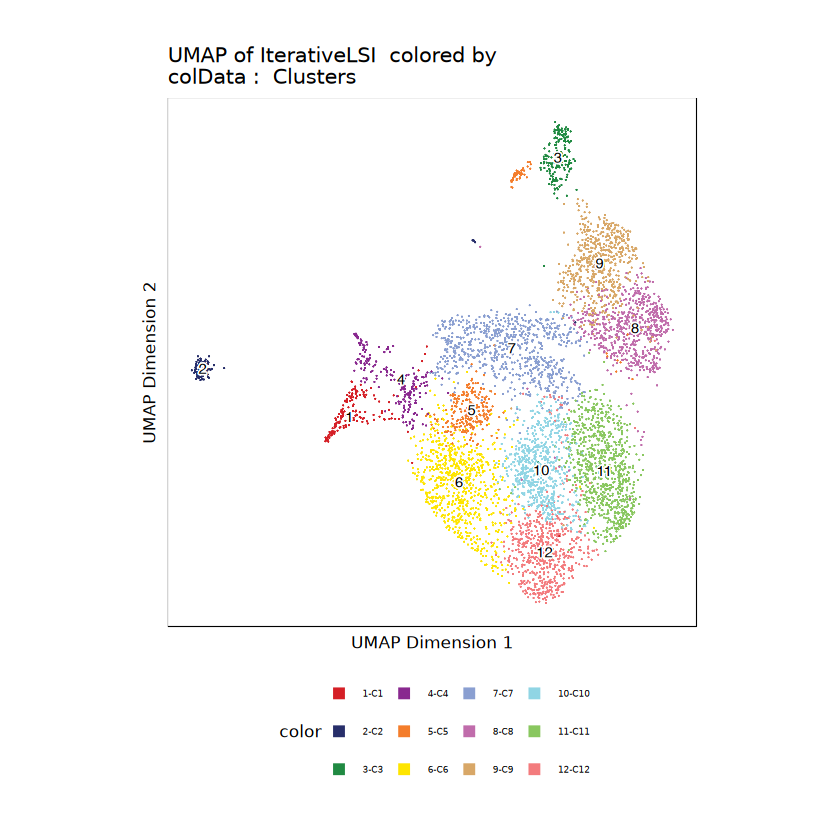

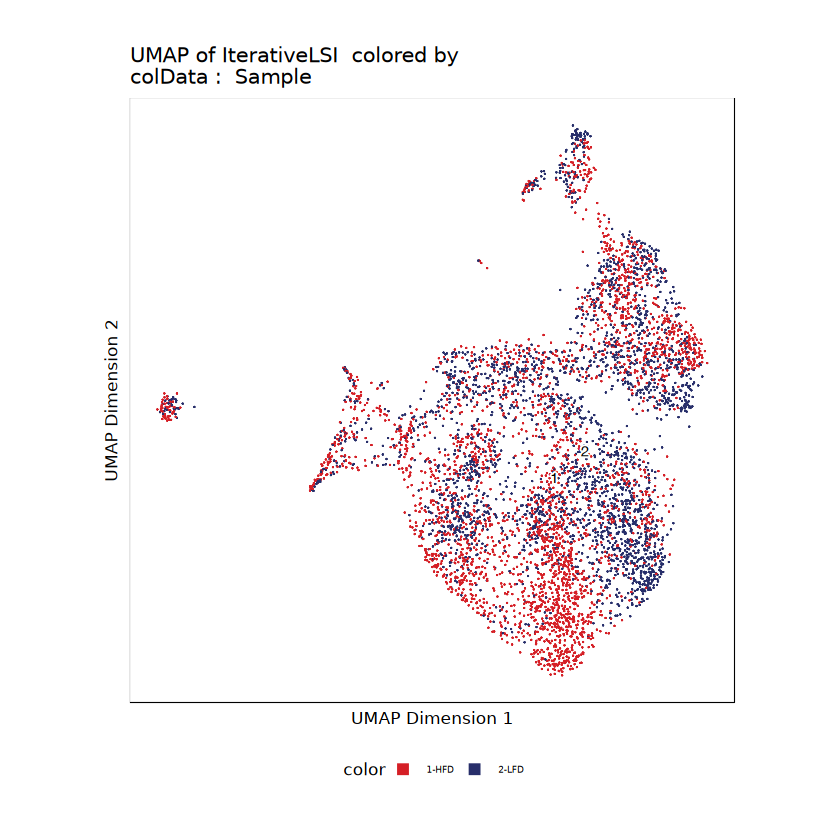

In [12]:
proj <- addUMAP(
  ArchRProj = proj,
)
plotEmbedding(ArchRProj = proj, colorBy = "cellColData", name = "Clusters")
plotEmbedding(proj, colorBy = "cellColData", name = "Sample")  

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”
ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f63e8d6549-Date-2026-01-13_Time-05-52-04.743931.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:52:04.877019 : 



Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f63e8d6549-Date-2026-01-13_Time-05-52-04.743931.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f634f4bbb4-Date-2026-01-13_Time-05-52-05.78997.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:52:05.949315 : 



Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f634f4bbb4-Date-2026-01-13_Time-05-52-05.78997.log

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f62f

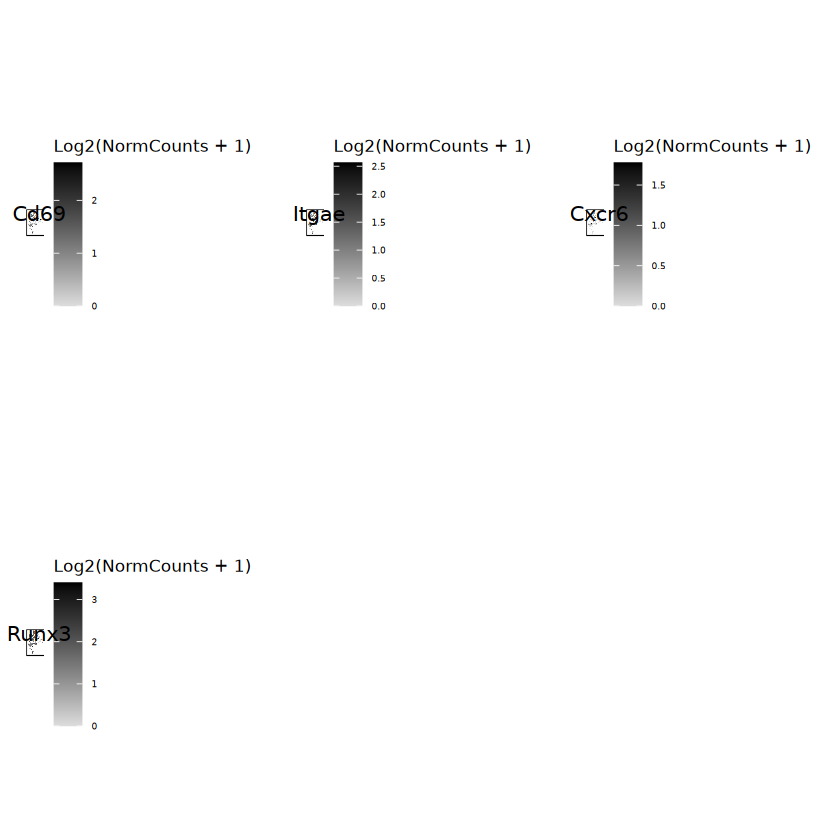

In [13]:
# Extract UMAP coordinates and metadata first to get consistent axis ranges
umap_df <- getEmbedding(ArchRProj = proj, embedding = "UMAP", returnDF = TRUE)
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

cell_col_data <- getCellColData(proj)
umap_df$Sample <- cell_col_data$Sample
umap_df$Clusters <- cell_col_data$Clusters

# Get cluster colors using ArchR's palette
unique_clusters <- sort(unique(umap_df$Clusters))
cluster_colors <- paletteDiscrete(values = unique_clusters, set = "stallion")
names(cluster_colors) <- unique_clusters

# Get consistent axis limits for all plots
x_range <- range(umap_df$UMAP1)
y_range <- range(umap_df$UMAP2)

# Set consistent dot size and alpha (increased size)
dot_size <- 1.0
dot_alpha <- 0.7

# Common theme elements
common_theme <- theme_minimal() +
  theme(
    panel.grid = element_blank(),
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    plot.title = element_text(hjust = 0.5, size = 18, face = "bold"),
    panel.background = element_rect(fill = "white"),
    panel.border = element_blank(),
    axis.line = element_blank()
  )

# Panel A: Full UMAP with 12 clusters (using ggplot directly to match other panels)
pA <- ggplot(umap_df, aes(x = UMAP1, y = UMAP2, color = Clusters)) +
  geom_point(size = dot_size, alpha = dot_alpha) +
  scale_color_manual(values = cluster_colors) +
  common_theme +
  labs(title = "UMAP") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range) +
  guides(color = guide_legend(override.aes = list(size = 3)))

# Extract legend separately
pA_with_legend <- ggplot(umap_df, aes(x = UMAP1, y = UMAP2, color = Clusters)) +
  geom_point(size = dot_size, alpha = dot_alpha) +
  scale_color_manual(values = cluster_colors) +
  theme_minimal() +
  theme(
    legend.position = "right",
    legend.text = element_text(size = 16),
    legend.title = element_text(size = 18, face = "plain")
  )

legend_A <- cowplot::get_legend(pA_with_legend)
legend_plot <- cowplot::ggdraw() + 
  cowplot::draw_plot(legend_A, x = 0, y = 0, width = 1, height = 1)

# Panel B: LFD only (light gray for LFD)
umap_df_lfd <- umap_df[umap_df$Sample == "LFD", ]

pB <- ggplot(umap_df_lfd, aes(x = UMAP1, y = UMAP2)) +
  geom_point(color = "#b3b6b6", size = dot_size, alpha = dot_alpha) +
  common_theme +
  labs(title = "LFD") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range)

# Panel C: HFD only (dark red for HFD)
umap_df_hfd <- umap_df[umap_df$Sample == "HFD", ]

pC <- ggplot(umap_df_hfd, aes(x = UMAP1, y = UMAP2)) +
  geom_point(color = "#c20922", size = dot_size, alpha = dot_alpha) +
  common_theme +
  labs(title = "HFD") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range)

# Panel D: Combined with cluster 12 in specified color, all others grey
cluster12_data <- umap_df[umap_df$Clusters == "C12", ]
all_data <- umap_df

pD <- ggplot() +
  geom_point(data = all_data[all_data$Clusters != "C12", ], 
             aes(x = UMAP1, y = UMAP2), 
             color = "grey", size = dot_size, alpha = dot_alpha) +
  geom_point(data = cluster12_data, 
             aes(x = UMAP1, y = UMAP2), 
             color = "#f37b7d", size = dot_size, alpha = dot_alpha) +
  stat_density_2d(data = cluster12_data, aes(x = UMAP1, y = UMAP2), 
                  inherit.aes = FALSE,
                  linetype = "dashed", color = "black", size = 0.5, 
                  bins = 5, alpha = 0.5) +
  common_theme +
  labs(title = "Combined (Cluster 12 outlined)") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range)

# Panel E: Heatmaps
genes_panelE <- c("Rorc", "Cxcr6", "Tcf7", "Ikzf2", "Il1r1", "Il10", "Il7r", "Runx3", "Irf4")
genes_panelE <- c("Cd69", "Itgae", "Cxcr6", "Runx3")

gene_plots <- list()
for (gene in genes_panelE) {
  p <- plotEmbedding(
    ArchRProj = proj,
    colorBy = "GeneScoreMatrix",
    name = gene,
    embedding = "UMAP",
    plotAs = "points",
    size = 0.5,
    imputeWeights = NULL
  ) 
  
  # Override color scale to blue-white-red
  p <- p + 
    theme_ArchR() + 
    theme(
      legend.position = "right",
      axis.title = element_blank(),
      axis.text = element_blank(),
      axis.ticks = element_blank(),
      plot.title = element_text(hjust = 0.5, size = 12, face = "italic")
    ) +
    labs(title = gene)
  
  # Replace the color scale
  p$scales$scales <- p$scales$scales[!sapply(p$scales$scales, function(x) "ScaleContinuous" %in% class(x))]
  p <- p + scale_color_gradient2(low = "#dddddd", mid = "#dddddd", high = "#000000")
  
  gene_plots[[gene]] <- p
}

# Combine Panel E plots
pE <- do.call(grid.arrange, c(gene_plots, ncol = 3))

# Save individual panels as SVG
ggsave("panelA_umap_clusters.svg", pA, width = 10, height = 8, dpi = 300)
ggsave("panelA_legend.svg", legend_plot, width = 3, height = 8, dpi = 300)
ggsave("panelB_umap_lfd.svg", pB, width = 10, height = 8, dpi = 300)
ggsave("panelC_umap_hfd.svg", pC, width = 10, height = 8, dpi = 300)
ggsave("panelD_umap_combined_cluster12.svg", pD, width = 10, height = 8, dpi = 300)
ggsave("Extended data 15_additional_genes.svg", pE, width = 15, height = 12, dpi = 300)

In [14]:
umap_df <- getEmbedding(ArchRProj = proj, embedding = "UMAP", returnDF = TRUE)
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

cell_col_data <- getCellColData(proj)
umap_df$Clusters <- cell_col_data$Clusters

# Get cluster colors using ArchR's palette
unique_clusters <- sort(unique(umap_df$Clusters))
cluster_colors <- paletteDiscrete(values = unique_clusters, set = "stallion")
names(cluster_colors) <- unique_clusters

# Panel A: UMAP with no labels
pA <- ggplot(umap_df, aes(x = UMAP1, y = UMAP2, color = Clusters)) +
  geom_point(size = 1.0, alpha = 0.7) +
  scale_color_manual(values = cluster_colors) +
  theme_minimal() +
  theme(
    panel.grid = element_blank(),
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    plot.title = element_blank(),
    panel.background = element_rect(fill = "white"),
    panel.border = element_blank(),
    axis.line = element_blank(),
    legend.position = "none"
  ) +
  coord_fixed(ratio = 1)

# Save
ggsave("panelA_no_labels.svg", pA, width = 10, height = 8, dpi = 300)

# Calculate top markers per cluster

Calculate top markers for each cluster (gene-level scores - imputed gene expression from chromatin accessibility)

In [15]:
markers <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Clusters",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-75f62962c0af-Date-2026-01-13_Time-05-52-16.858656.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2026-01-13 05:52:16.959827 : Matching Known Biases, 0.001 mins elapsed.

###########
2026-01-13 05:54:09.429811 : Completed Pairwise Tests, 1.876 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-75f62962c0af-Date-2026-01-13_Time-05-52-16.858656.log



In [16]:
genes_all_clusters <- getMarkers(markers, cutOff = "FDR <= 1")

Save all significant (FDR < 0.05) markers as csv

In [17]:
for(i in 1:12) {
    cluster_data <- genes_all_clusters[[i]]
    
    # Filter for significant genes
    genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05, ]
    
    # Optional: Add fold change filtering
    # genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & abs(cluster_data$Log2FC) > 1, ]
    
    # Save 
    filename <- paste0("significant_genes_per_cluster/cluster_", i, "_significant_genes.csv")
    write.csv(genes_clusters_sig, filename, row.names = FALSE)
    
    print(paste("Cluster", i, ":", nrow(genes_clusters_sig), "significant genes saved to", filename))
}

[1] "Cluster 1 : 11203 significant genes saved to significant_genes_per_cluster/cluster_1_significant_genes.csv"
[1] "Cluster 2 : 3578 significant genes saved to significant_genes_per_cluster/cluster_2_significant_genes.csv"
[1] "Cluster 3 : 3835 significant genes saved to significant_genes_per_cluster/cluster_3_significant_genes.csv"
[1] "Cluster 4 : 8573 significant genes saved to significant_genes_per_cluster/cluster_4_significant_genes.csv"
[1] "Cluster 5 : 582 significant genes saved to significant_genes_per_cluster/cluster_5_significant_genes.csv"
[1] "Cluster 6 : 4276 significant genes saved to significant_genes_per_cluster/cluster_6_significant_genes.csv"
[1] "Cluster 7 : 3587 significant genes saved to significant_genes_per_cluster/cluster_7_significant_genes.csv"
[1] "Cluster 8 : 5098 significant genes saved to significant_genes_per_cluster/cluster_8_significant_genes.csv"
[1] "Cluster 9 : 5567 significant genes saved to significant_genes_per_cluster/cluster_9_significant_gen

Top markers HFD vs LFD

In [18]:
markers_condition <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "Sample",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-75f6119112bb-Date-2026-01-13_Time-05-54-12.512923.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2026-01-13 05:54:12.672865 : Matching Known Biases, 0.001 mins elapsed.

###########
2026-01-13 05:54:30.315982 : Completed Pairwise Tests, 0.295 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-75f6119112bb-Date-2026-01-13_Time-05-54-12.512923.log



In [19]:
top_genes_per_sample <- getMarkers(markers_condition, cutOff = "FDR <= 1")

In [20]:
top_genes_per_sample

List of length 2
names(2): HFD LFD

In [21]:
for(i in 1:2) {
    cluster_data <- top_genes_per_sample[[i]]
    
    # Filter for significant genes
    genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & cluster_data$Log2FC > 1, ]
    
    # Optional: Add fold change filtering
    # genes_clusters_sig <- cluster_data[cluster_data$FDR < 0.05 & abs(cluster_data$Log2FC) > 1, ]
    
    # Save
    if(i == 1) {
        filename <- "significant_genes_per_condition/significant_genes_hfd.csv"
    } else {
        filename <- "significant_genes_per_condition/significant_genes_lfd.csv"
    }
    write.csv(genes_clusters_sig, filename, row.names = FALSE)
    
    print(paste(i, ":", nrow(genes_clusters_sig), "significant genes saved to", filename))
}

[1] "1 : 30 significant genes saved to significant_genes_per_condition/significant_genes_hfd.csv"
[1] "2 : 13 significant genes saved to significant_genes_per_condition/significant_genes_lfd.csv"


# Cluster identification

Define markers of interest that help us define the clusters. Two lists (markerGenes and additionalGenes) that can be modified as needed.

In [22]:
markerGenes <- c("Cd69",
"Gata3",
"Foxp3",
"Tbx21",
"Rorc",
"Nr1d1",
"Il2",
"Stat3",
# "Stat5",
"Irf4",
"Cd44",
"Sell",
"Il17a",
"Il17f",
"Il22",
"Il21",
"Il23r",
"Il1r1",
"Ikzf2",
"Icos",
"Il1r2",
"Tox",
"Pparg",
"Rora",
"Il19",
"Il1rl1",
"Il7r",
"Il2ra",
"Ifng",
"Cat",
"S1pr1",
"Bcl2",
"Klf2",
"Ccr7",
"Il5",
"Il13")

In [23]:
additionalGenes <- c("Itgae", "Itga1", "Runx3", "Prdm1", "Cxcr6", "Ifng", "Tnf", "Il2ra", "Il10", "Bcl2", "Bcl2a1a", "Il7r", "Nr4a1", "Fabp4", "Fabp5", "Ccr6", "Ccr7", "Ccr8", "Ccr10", "S1pr1", "Sell", "Tcf7", "Lef1", "Eomes", "Tbx21", "Rorc", "Gzmb", "Prf1", "Cd69", "Batf", "Il1r1")

Calculate gene score for each gene in the markerGenes list. 

In [24]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f6192f4dba-Date-2026-01-13_Time-05-54-31.086366.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:54:31.244188 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f6192f4dba-Date-2026-01-13_Time-05-54-31.086366.log



Plot the gene score on UMAP

Warning message:
“The `<scale>` argument of `guides()` cannot be `FALSE`. Use "none" instead as
of ggplot2 3.3.4.”


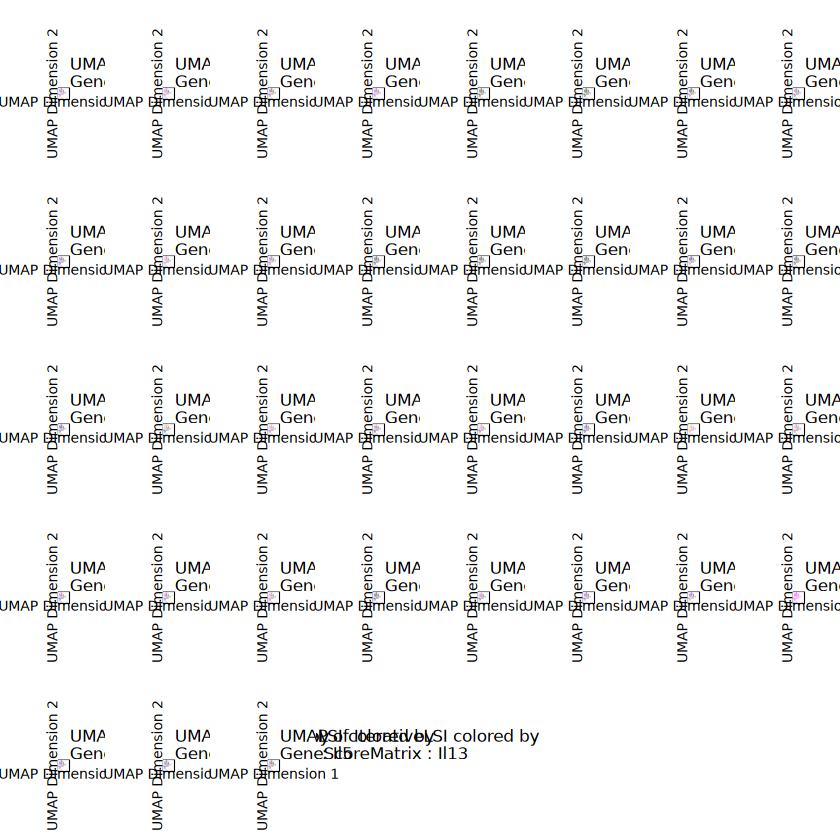

In [25]:
p2 <- lapply(p, function(x){
    x + guides(color = FALSE, fill = FALSE) + 
    theme_ArchR(baseSize = 8) +
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank()
    ) 
})

combined_plot <- do.call(gridExtra::grid.arrange, c(p2, ncol = 8))

# Save
ggsave("plots/combined_plot_RAW.pdf", combined_plot, width = 30, height = 20, units = "in", dpi = 300)

Gene score plots are quite variable - this is just because of the sparsity of the snATACseq data (most genes have no accessibility signal in most cells). We use MAGIC to impute gene scores (inbuilt in ArchR; it smoothes the signal across nearby cells).

In [26]:
proj <- addImputeWeights(proj)


ArchR logging to : ArchRLogs/ArchR-addImputeWeights-75f65ed81088-Date-2026-01-13_Time-05-54-42.956785.log
If there is an issue, please report to github with logFile!

2026-01-13 05:54:42.991888 : Computing Impute Weights Using Magic (Cell 2018), 0 mins elapsed.



Get imputed gene scores for all genes and plot markerGenes on UMAP

In [27]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    imputeWeights = getImputeWeights(proj),
    force = TRUE
)

Getting ImputeWeights

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f6292388a9-Date-2026-01-13_Time-05-54-45.867338.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:54:46.003857 : 



Imputing Matrix

Using weights on disk

1 of 1

Using weights on disk

1 of 1

Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f6292388a9-Date-2026-01-13_Time-05-54-45.867338.log



Plot the new imputed weights with a fixed scale (to make the gene score levels comparable)

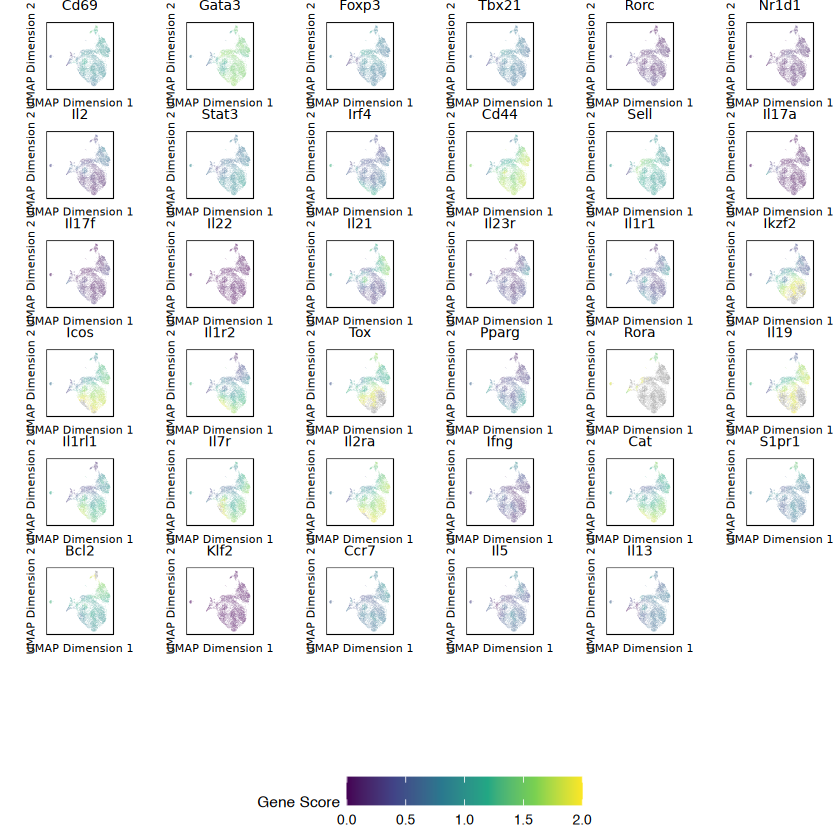

In [28]:
# Apply fixed scale from 0 to 2 to all plots
p2 <- lapply(p, function(x){
    # Remove any existing scales 
    x$scales$scales <- list()
    
    x + 
    scale_color_viridis_c(
        limits = c(0, 2),  # Changed to 0-2 
        name = "Gene Score"
    ) +
    scale_fill_viridis_c(
        limits = c(0, 2),  # Changed to 0-2 
    ) +
    guides(color = FALSE, fill = FALSE) +  # Remove all legends
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0, 0, 0, 0), "cm")) +
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5)
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    # Extract gene name
    gene_name <- names(p)[i] 
    
    p2[[i]] + ggtitle(gene_name)
})

# Create a dummy plot with the gene score scale to extract the legend
dummy_data <- data.frame(x = 1:100, y = 1:100, value = seq(0, 2, length.out = 100))
legend_plot <- ggplot(dummy_data, aes(x = x, y = y, color = value)) +
    geom_point() +
    scale_color_viridis_c(  # Changed to viridis
        limits = c(0, 2),
        name = "Gene Score"
    ) +
    theme_void() +
    theme(legend.position = "bottom",
          legend.key.width = unit(1, "cm"),
          legend.text = element_text(size = 8),
          legend.title = element_text(size = 9))

# Extract the legend
legend <- cowplot::get_legend(legend_plot)

# Create the main plot grid 
main_plot <- do.call(cowplot::plot_grid, c(list(ncol = 6), p2[1:40]))

# Combine main plot with legend below
cowplot::plot_grid(main_plot, legend, 
                   ncol = 1, 
                   rel_heights = c(1, 0.1))

Same plots but with individual scales for each gene

In [29]:
p <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = markerGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f61f1aa7e8-Date-2026-01-13_Time-05-54-58.433415.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:54:58.578883 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 
32 
33 
34 
35 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f61f1aa7e8-Date-2026-01-13_Time-05-54-58.433415.log



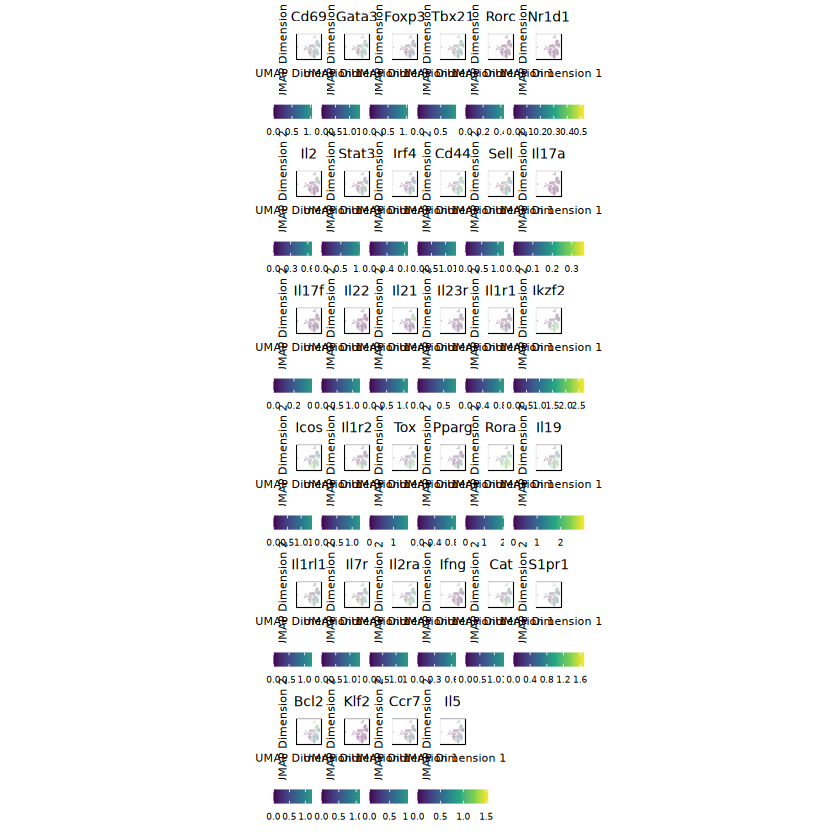

In [30]:
p2 <- lapply(p, function(x){
    x$scales$scales <- list()
    
    x + 
    scale_color_viridis_c(
        name = ""  
    ) +
    scale_fill_viridis_c(
        name = "" 
    ) +
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm")) +  
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5),
        legend.key.size = unit(0.3, "cm"), 
        legend.text = element_text(size = 5),  
        legend.title = element_blank(),  
        legend.position = "bottom"  # Legend at bottom
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    gene_name <- names(p)[i] 
    p2[[i]] + ggtitle(gene_name)
})

# Create the grid using patchwork with individual legends
combined_plot <- wrap_plots(p2[1:34], ncol = 6)

# Display
print(combined_plot)

# Save with even larger dimensions for bigger plots
ggsave("plots/gene_plots_individual_scales.pdf", combined_plot, 
       width = 15, height = 20, 
       units = "in", dpi = 300)

Same with list of additional genes.

In [31]:
p_additionalgenes <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = additionalGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f6409ef55f-Date-2026-01-13_Time-05-55-12.689694.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:55:12.848527 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f6409ef55f-Date-2026-01-13_Time-05-55-12.689694.log



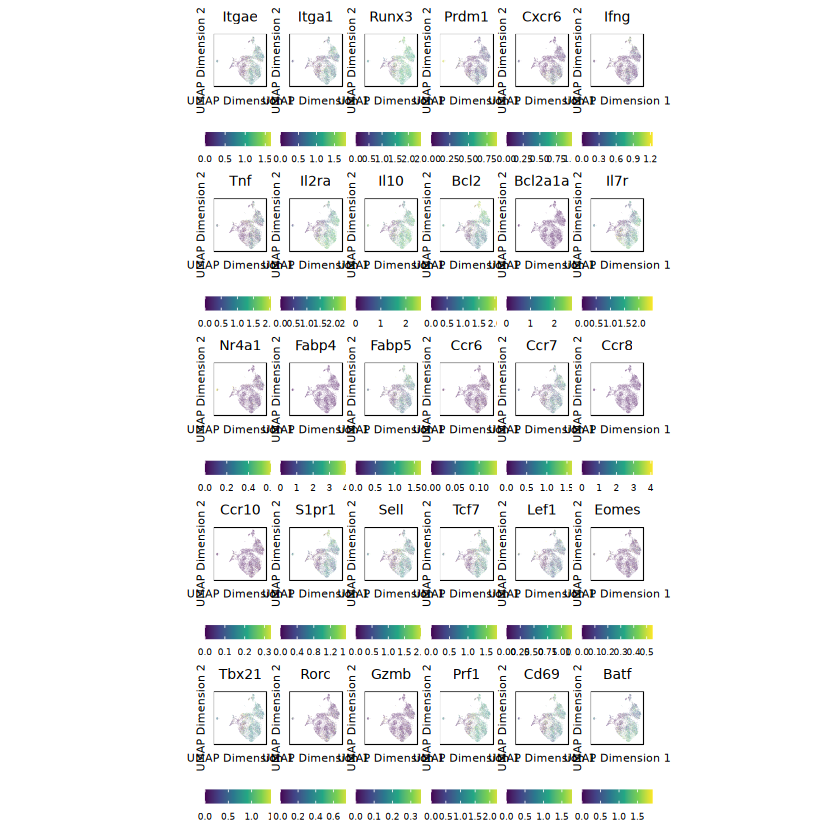

In [32]:
p2 <- lapply(p_additionalgenes, function(x){
    x$scales$scales <- list()
    x$layers[[1]]$aes_params$size <- 2
    
    x + 
    scale_color_viridis_c(
        name = "" 
    ) +
    scale_fill_viridis_c(
        name = "" 
    ) +
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm")) +  
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5),
        legend.key.size = unit(0.3, "cm"), 
        legend.text = element_text(size = 5),  
        legend.title = element_blank(),  
        legend.position = "bottom"  # Legend at bottom
    )
})

# Clean up titles to show only gene names
p2 <- lapply(seq_along(p2), function(i) {
    gene_name <- names(p_additionalgenes)[i] 
    p2[[i]] + ggtitle(gene_name)
})

# Create the grid using patchwork with individual legends
combined_plot <- wrap_plots(p2[1:30], ncol = 6)

# Display
print(combined_plot)

# Save 
ggsave("plots/gene_plots_individual_scales_additionalgenes.pdf", combined_plot, 
       width = 8, height = 12, 
       units = "in", dpi = 300)

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f63a1efbfb-Date-2026-01-13_Time-05-55-25.752152.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-13 05:55:25.901341 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 
25 
26 
27 
28 
29 
30 
31 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f63a1efbfb-Date-2026-01-13_Time-05-55-25.752152.log



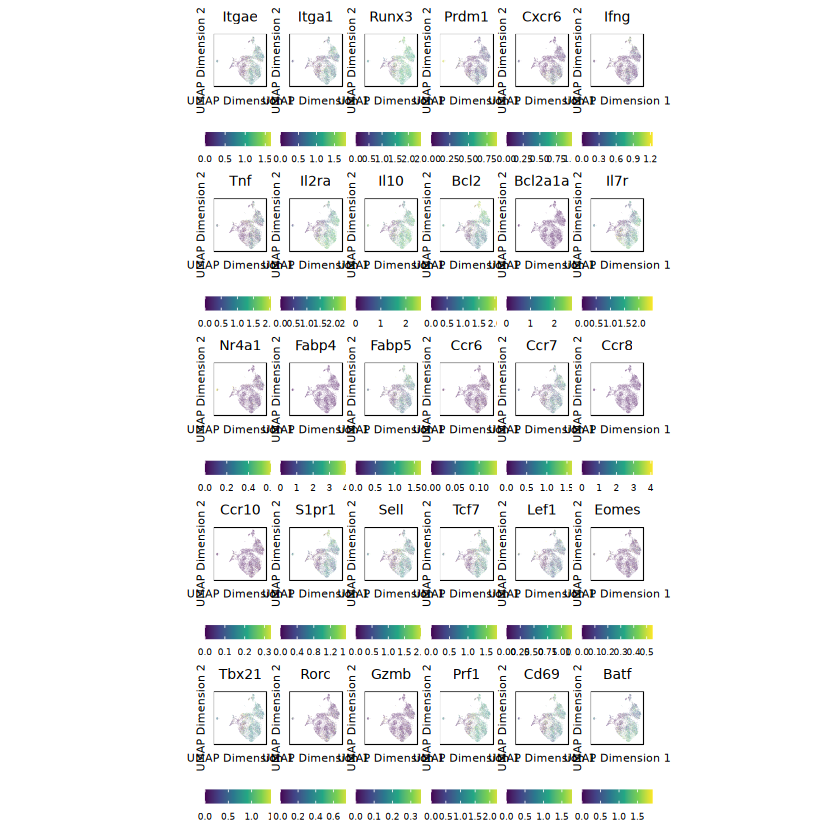

In [33]:
# First, create the gene plots using the filtered project
p_additionalgenes_filtered <- plotEmbedding(
    ArchRProj = proj, 
    colorBy = "GeneScoreMatrix", 
    name = additionalGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    force = TRUE
)

# Then apply your formatting
p2 <- lapply(p_additionalgenes_filtered, function(x){
    x$scales$scales <- list()
    x$layers[[1]]$aes_params$size <- 2
    
    x + 
    scale_color_viridis_c(name = "") +
    scale_fill_viridis_c(name = "") +
    theme_ArchR(baseSize = 6.5) +
    theme(plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm")) +  
    theme(
        axis.text.x=element_blank(), 
        axis.ticks.x=element_blank(), 
        axis.text.y=element_blank(), 
        axis.ticks.y=element_blank(),
        plot.title = element_text(size = 8, hjust = 0.5),
        legend.key.size = unit(0.3, "cm"), 
        legend.text = element_text(size = 5),  
        legend.title = element_blank(),  
        legend.position = "bottom"
    )
})

# Clean up titles
p2 <- lapply(seq_along(p2), function(i) {
    gene_name <- names(p_additionalgenes_filtered)[i] 
    p2[[i]] + ggtitle(gene_name)
})

# Create grid
combined_plot <- wrap_plots(p2[1:30], ncol = 6)

print(combined_plot)

ggsave("plots/gene_plots_ALL CLUSTERS_filtered_additionalgenes.pdf", combined_plot, 
       width = 8, height = 12, units = "in", dpi = 300)

## Calculate top 10 markers per cluster

In [34]:
marker_data <- assays(markers)$Log2FC
marker_fdr <- assays(markers)$FDR
gene_names <- rowData(markers)$name

# Find significant markers for each cluster
significant_markers <- which(marker_fdr <= 0.01 & marker_data >= 1.0)

# Get top markers for each cluster
top_markers_per_cluster <- list()
for(i in 1:ncol(markers)) {
    cluster_markers <- which(marker_fdr[,i] <= 0.01 & marker_data[,i] >= 1.0)
    top_cluster <- cluster_markers[order(marker_data[cluster_markers,i], decreasing = TRUE)]
    top_markers_per_cluster[[i]] <- gene_names[top_cluster[1:10]]  # Top 10 per cluster
}

In [35]:
top_markers_per_cluster

[[1]]
 [1] "Olfr480"       "Mir5107"       "Ccdc89"        "Rpl8"         
 [5] "Olfr1392"      "Mansc4"        "Olfr1417"      "Cypt12"       
 [9] "A230056P14Rik" "Olfr1294"     

[[2]]
 [1] "Aqp12"         "Mir148b"       "Olfr750"       "Olfr1441"     
 [5] "Il1bos"        "Olfr1410"      "Urad"          "Ctsll3"       
 [9] "A730036I17Rik" "Copz1"        

[[3]]
 [1] "Pdx1"          "Mir7k"         "Cxcl10"        "Mrps18c"      
 [5] "Nprl2"         "Neu4"          "Gm13271"       "Polg2"        
 [9] "4930412B13Rik" "Mir101a"      

[[4]]
 [1] "B130024G19Rik" "Gab3"          "Gm38425"       "Mir30c-2"     
 [5] "DQ267102"      "Ugt2b36"       "Olfr846"       "4930517E11Rik"
 [9] "0610039K10Rik" "Mir124a-2"    

[[5]]
 [1] "Klri2"   "Egfem1"  "Ramp3"   "Snora5c" "Tbrg4"   "Wap"     "Abcb4"  
 [8] "Gm11978" "Slc4a10" "Il21"   

[[6]]
 [1] "Tmem42"   "Scgb2b19" "Tmco1"    "Mir195b"  "Olfr1173" "Mmp3"    
 [7] "Skint9"   "Atp2c2"   "Muc15"    "Mir3099" 

[[7]]
 [1] "Trir"          "1700041M19Rik" "Fxyd4"         "Nipsnap3a"    
 [5] "Prss16"        "Gkn3"          "Dsc3"          "Cpne2"        
 [9] "Pgr15l"        "Spata16"      

[[8]]
 [1] "Cygb"          "Ccl20"         "Cetn4"         "Lipo1"        
 [5] "Aoc2"          "Cidec"         "2410004B18Rik" "Prcd"         
 [9] "B830017H08Rik" "Olfr315"      

[[9]]
 [1] "Olfr819"       "Olfr157"       "Serpina9"      "Gm20939"      
 [5] "Mir7077"       "Neu4"          "Heatr9"        "Pdzd9"        
 [9] "Bcl10"         "1700109G14Rik"

[[10]]
 [1] "Fkbp8"         "Ltb4r1"        "Rnu73b"        "Ltb4r2"       
 [5] "Prps1l1"       "Prkar1a"       "2310030A07Rik" "Gm10768"      
 [9] "Atp5g1"        "Kxd1"         

[[11]]
 [1] "Mrgpra9" "Galnt6"  "Poli"    "Vsx1"    "Csrp3"   "Slc19a1" "Rmnd5b" 
 [8] "Mir326"  "Snhg3"   "Mir7056"

[[12]]
 [1] "Edf1"    "Gm16062" "Mavs"    "Ap5s1"   "Khdc1b"  "Timd2"   "Ppbp"   
 [8] "Prorsd1" "Eef1b2"  "Snora41"

## Plot conditions on UMAP

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f6f1b4546-Date-2026-01-13_Time-05-55-39.506956.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = cellColData

Plotting Embedding

1 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f6f1b4546-Date-2026-01-13_Time-05-55-39.506956.log



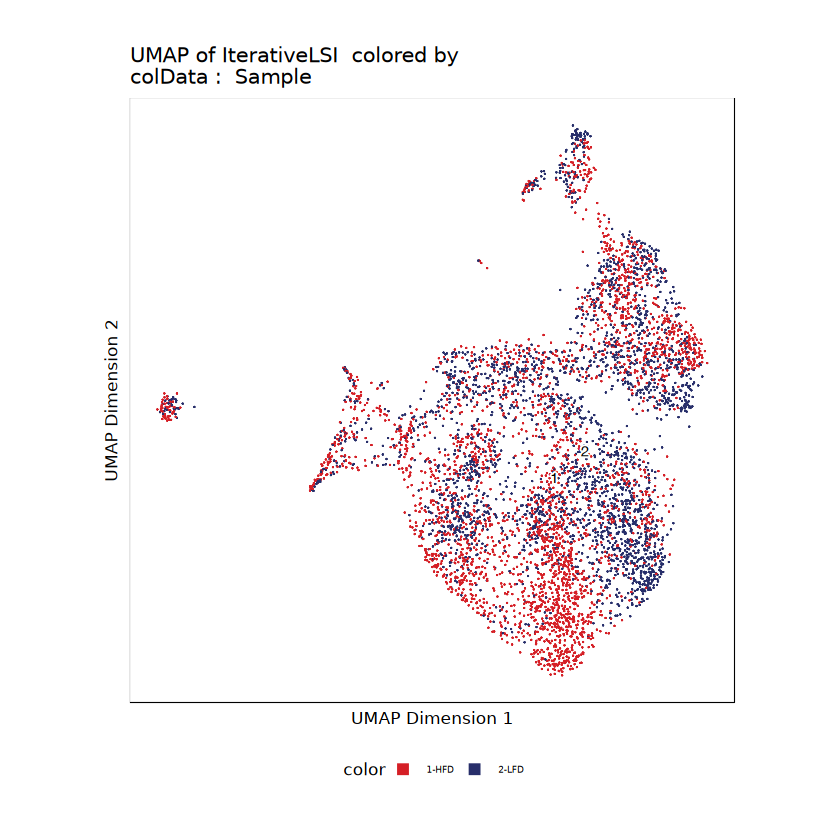

In [36]:
plotEmbedding(ArchRProj = proj, 
              colorBy = "cellColData", 
              name = "Sample",
              embedding = "UMAP",
              force = TRUE)

Calculate the number of cells per cluster and condition.

In [37]:
table(getCellColData(proj)$Clusters, getCellColData(proj)$Sample)

     
      HFD LFD
  C1  104  62
  C10 365 282
  C11 213 656
  C12 561  45
  C2   56  34
  C3   80  98
  C4  138  63
  C5  145 142
  C6  467 269
  C7  304 452
  C8  323 315
  C9  282 295

# DARs

Calculate top DARs (peak-level accessibility - actual chromatin accessibility at specific genomic regions)

In [38]:
DARs <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "PeakMatrix",
  groupBy = "Sample",  
  bias = c("TSSEnrichment", "log10(nFrags)"),
  testMethod = "wilcoxon",
)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-75f6513e80f0-Date-2026-01-13_Time-05-55-40.288374.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2026-01-13 05:55:40.385718 : Matching Known Biases, 0.001 mins elapsed.

###########
2026-01-13 05:55:57.139237 : Completed Pairwise Tests, 0.28 mins elapsed.
###########

ArchR logging successful to : ArchRLogs/ArchR-getMarkerFeatures-75f6513e80f0-Date-2026-01-13_Time-05-55-40.288374.log



Select DARs with FDR < 0.1 and Log2FC > 1 & plot 

In [39]:
hfd_dar <- plotMarkers(seMarker = DARs, name = "HFD", cutOff = "FDR <= 0.1 & Log2FC >= 1", plotAs = "MA")
lfd_dar <- plotMarkers(seMarker = DARs, name = "LFD", cutOff = "FDR <= 0.1 & Log2FC >= 1", plotAs = "MA")


Warning message:
“Removed 4 rows containing missing values or values outside the scale range
(`geom_point_rast()`).”


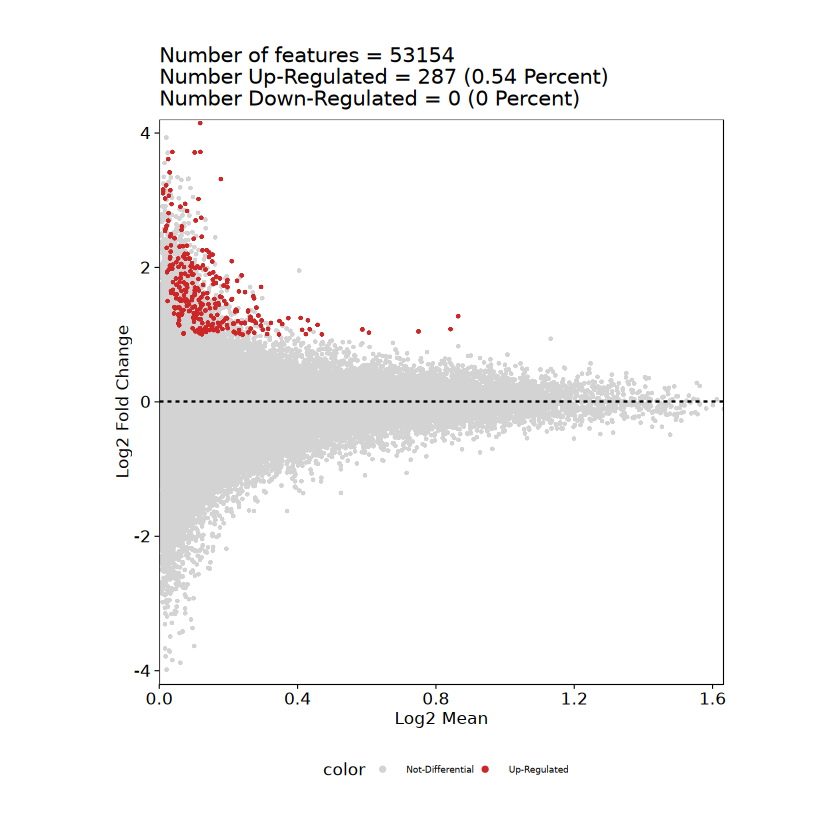

In [40]:
hfd_dar

Warning message:
“Removed 19 rows containing missing values or values outside the scale range
(`geom_point_rast()`).”


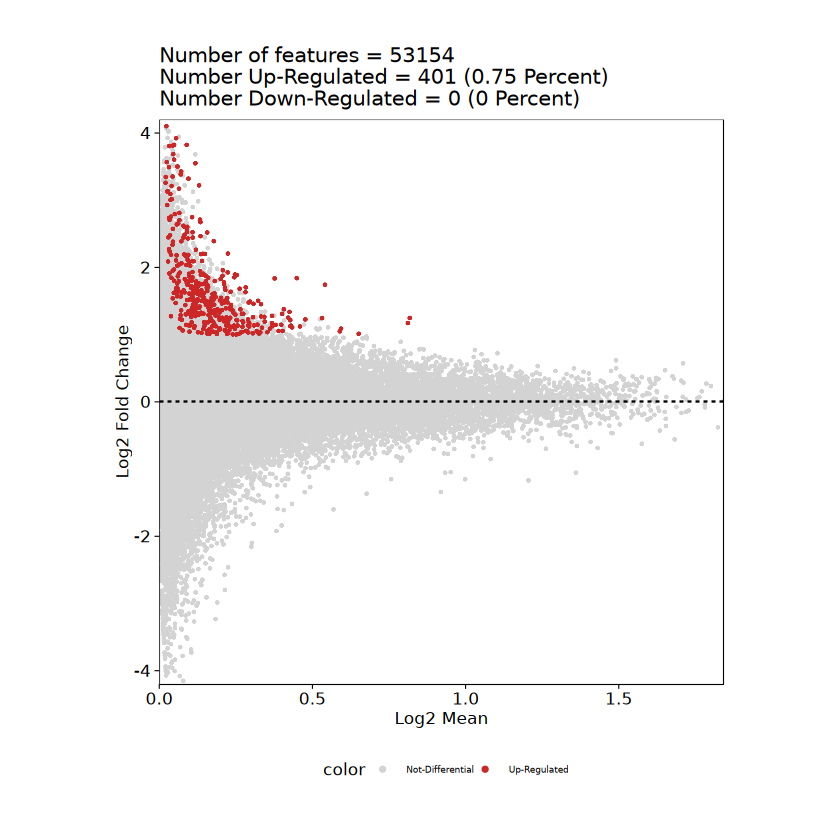

In [41]:
lfd_dar

Define function to plot the volcano plot displaying DARs in HFD vs. LFD.

In [42]:
create_volcano_plot <- function(DARs, 
                               title = "Volcano Plot", 
                               xlab = "Log2 Fold Change", 
                               up_label = "Up", 
                               down_label = "Down",
                               log2fc_threshold = 1,
                               fdr_threshold = 0.05) {
    
    # Extract data from the DAR results
    dar_data <- assay(DARs, "Log2FC")
    dar_fdr <- assay(DARs, "FDR")
    
    if(is.list(dar_data)) {
        log2fc <- as.numeric(dar_data[[1]])
        fdr <- as.numeric(dar_fdr[[1]])
    } else {
        log2fc <- as.numeric(as.vector(dar_data))
        fdr <- as.numeric(as.vector(dar_fdr))
    }
    
    # Check for any issues
    print(paste("Log2FC range:", range(log2fc, na.rm = TRUE)))
    print(paste("FDR range:", range(fdr, na.rm = TRUE)))
    
    # Remove any NA values
    valid_indices <- !is.na(log2fc) & !is.na(fdr)
    log2fc <- log2fc[valid_indices]
    fdr <- fdr[valid_indices]
    
    # Create manual volcano plot
    plot(log2fc, -log10(fdr), 
         pch = 20, cex = 0.5, col = "grey", alpha = 0.6,
         xlab = xlab, ylab = "-log10(FDR)",
         main = title)
    
    # Add colored points for significant DARs
    significant_up <- log2fc > log2fc_threshold & fdr < fdr_threshold
    significant_down <- log2fc < -log2fc_threshold & fdr < fdr_threshold
    
    points(log2fc[significant_up], -log10(fdr[significant_up]), 
           pch = 20, cex = 0.8, col = "red")
    points(log2fc[significant_down], -log10(fdr[significant_down]), 
           pch = 20, cex = 0.8, col = "blue")
    
    # Add threshold lines
    abline(h = -log10(fdr_threshold), col = "black", lty = 2)
    abline(v = c(-log2fc_threshold, log2fc_threshold), col = "black", lty = 2)
    
    # Add legend
    legend("topright", legend = c(paste("Up in", up_label), 
                                 paste("Down in", up_label), 
                                 "Not significant"), 
           col = c("red", "blue", "grey"), pch = 20)
    
    # Return summary statistics
    return(list(
        total_points = length(log2fc),
        significant_up = sum(significant_up),
        significant_down = sum(significant_down),
        log2fc_range = range(log2fc),
        fdr_range = range(fdr)
    ))
}

[1] "Log2FC range: -4.70195222491363" "Log2FC range: 5.14722344668562" 
[1] "FDR range: 9.34098449584718e-07" "FDR range: 1"                   


Warning message in plot.window(...):
“"alpha" is not a graphical parameter”
Warning message in plot.xy(xy, type, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in axis(side = side, at = at, labels = labels, ...):
“"alpha" is not a graphical parameter”
Warning message in box(...):
“"alpha" is not a graphical parameter”
Warning message in title(...):
“"alpha" is not a graphical parameter”


$total_points
[1] 53145

$significant_up
[1] 152

$significant_down
[1] 227

$log2fc_range
[1] -4.701952  5.147223

$fdr_range
[1] 9.340984e-07 1.000000e+00

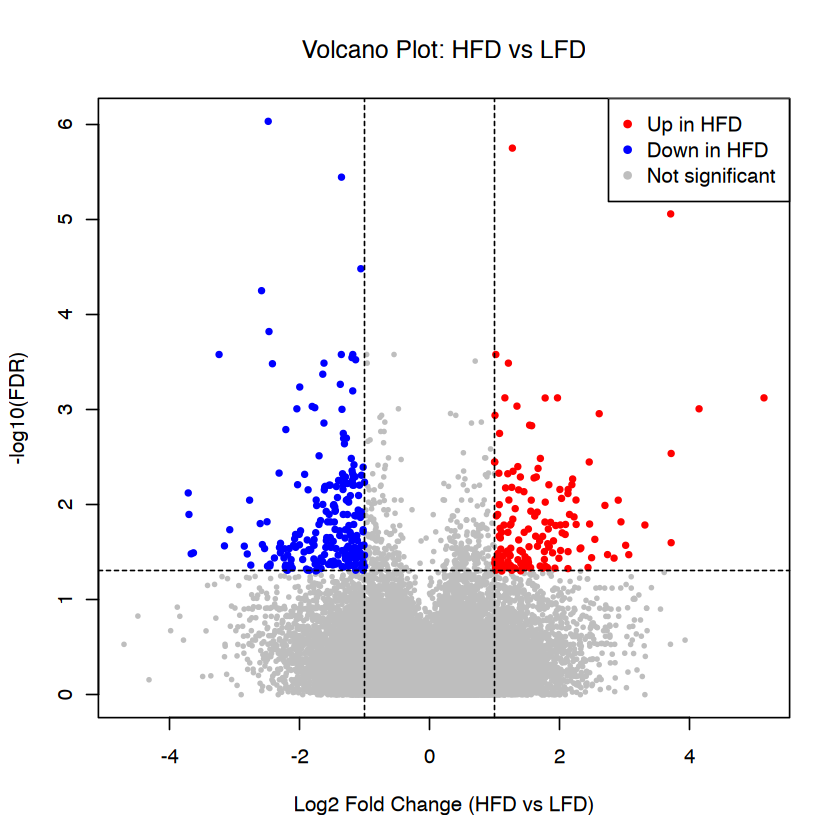

In [43]:
create_volcano_plot(DARs, 
                    title = "Volcano Plot: HFD vs LFD",
                    xlab = "Log2 Fold Change (HFD vs LFD)",
                    up_label = "HFD",
                    down_label = "LFD")

# Visualizations for figures

# Cell-type specific analysis 
(With merged clusters)

## Rename & replot clusters

In [91]:
proj$Clusters_renamed <- proj$Clusters
proj$Clusters_renamed[proj$Clusters_renamed %in% c("C1", "C4")] <- "Circulating T cells"
proj$Clusters_renamed[proj$Clusters_renamed == "C3"] <- "Circulating/Transitional"
proj$Clusters_renamed[proj$Clusters_renamed %in% c("C2", "C5", "C6", "C7", "C8", "C9", "C10", "C11", "C12", "C13")] <- "Tissue-resident T cells"

Check that renaming worked

In [92]:
table(proj$Clusters_renamed)



     Circulating T cells Circulating/Transitional  Tissue-resident T cells 
                     367                      178                     5206 

In [93]:
umap_df <- getEmbedding(ArchRProj = proj, embedding = "UMAP")

colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

umap_df$Clusters_renamed <- proj$Clusters_renamed

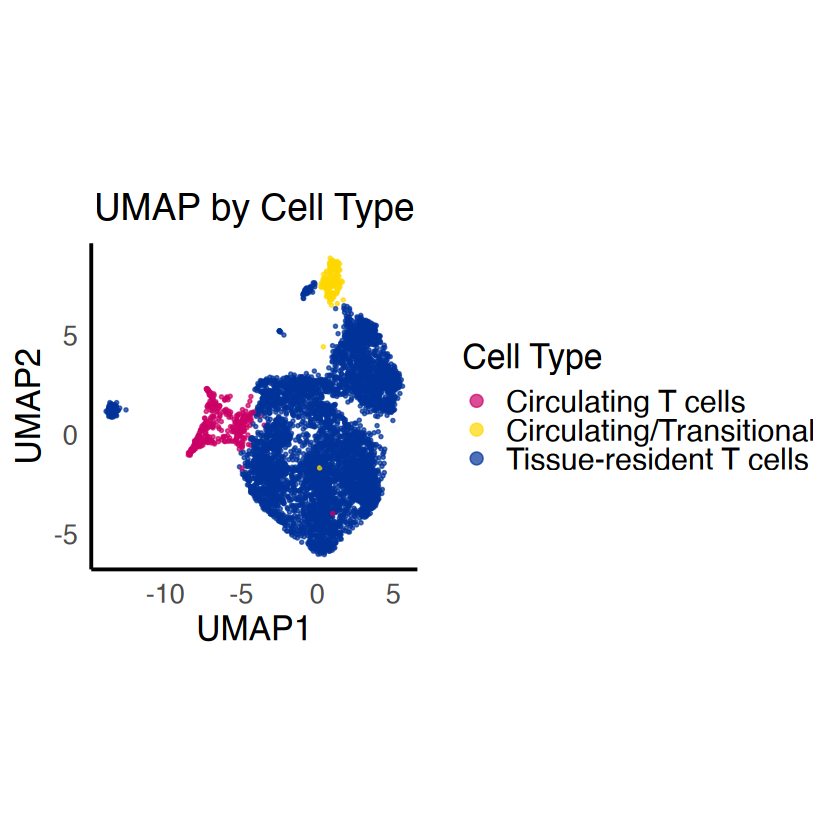

In [94]:
p1 <- ggplot(umap_df, aes(x = `UMAP1`, y = `UMAP2`, color = Clusters_renamed)) +
  geom_point(size = 0.5, alpha = 0.7) +
  scale_color_manual(values = c(
    "Tissue-resident T cells" = "#003399",
    "Circulating T cells" = "#cc0066", 
    "Circulating/Transitional" = "gold"
  )) +
  labs(
    title = "UMAP by Cell Type",
    color = "Cell Type",
    x = "UMAP1",
    y = "UMAP2"
  ) +
  theme_minimal(base_size = 18) +
  theme(
    panel.grid.minor = element_blank(),
    panel.grid.major = element_blank(),
    axis.line = element_line(color = "black"),
    aspect.ratio = 1,
    legend.title = element_text(size = 20),
    legend.text = element_text(size = 18),
    axis.title = element_text(size = 20),
    axis.text = element_text(size = 16),
    plot.title = element_text(size = 22, hjust = 0.5, face = "bold")
  ) +
  guides(color = guide_legend(override.aes = list(size = 3))) 

print(p1)

ggsave("plots/UMAP_cell_types.svg", p1, width = 10, height = 8, dpi = 300)

# Reclustering

Figure 4i, j

Dropping ImputeWeights Since You Are Subsetting Cells! ImputeWeights is a cell-x-cell Matrix!

Checking Inputs...

ArchR logging to : ArchRLogs/ArchR-addIterativeLSI-75f6584fcd97-Date-2026-01-13_Time-06-01-28.97281.log
If there is an issue, please report to github with logFile!

2026-01-13 06:01:29.203863 : Computing Total Across All Features, 0.001 mins elapsed.

2026-01-13 06:01:30.08699 : Computing Top Features, 0.016 mins elapsed.

###########
2026-01-13 06:01:31.313242 : Running LSI (1 of 2) on Top Features, 0.037 mins elapsed.
###########

2026-01-13 06:01:31.342007 : Creating Partial Matrix, 0.037 mins elapsed.

2026-01-13 06:01:39.861266 : Computing LSI, 0.179 mins elapsed.

Filtering 2 dims correlated > 0.75 to log10(depth + 1)

2026-01-13 06:01:57.312008 : Identifying Clusters, 0.47 mins elapsed.

2026-01-13 06:02:01.798224 : Identified 6 Clusters, 0.545 mins elapsed.

2026-01-13 06:02:01.801586 : Saving LSI Iteration, 0.545 mins elapsed.

2026-01-13 06:02:10.537897 : Creatin

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 5116
Number of edges: 199905

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7840
Number of communities: 10
Elapsed time: 0 seconds


2026-01-13 06:03:10.473048 : Testing Outlier Clusters, 0.078 mins elapsed.

2026-01-13 06:03:10.476051 : Assigning Cluster Names to 10 Clusters, 0.078 mins elapsed.

2026-01-13 06:03:10.524298 : Finished addClusters, 0.079 mins elapsed.

Filtering 2 dims correlated > 0.75 to log10(depth + 1)

06:03:10 UMAP embedding parameters a = 0.7669 b = 1.223

06:03:10 Read 5116 rows and found 28 numeric columns

06:03:10 Using Annoy for neighbor search, n_neighbors = 40

06:03:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

06:03:10 Writing NN index file to temp file /var/folders/3q/7dvjpgjs5ss2pc9rj8ffdjkm0000gn/T//RtmpS7FVXl/file75f69710a0f

06:03:10 Searching Annoy index using 4 threads, search_k = 4000

06:03:11 Annoy recall = 100%

06:03:11 Commencing smooth kNN distance 

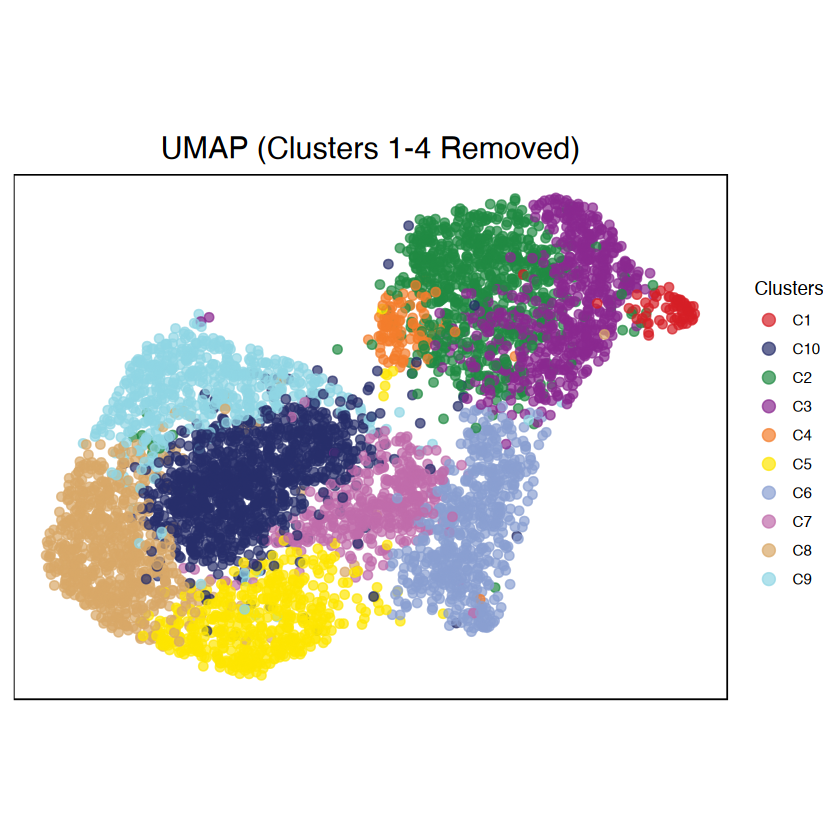

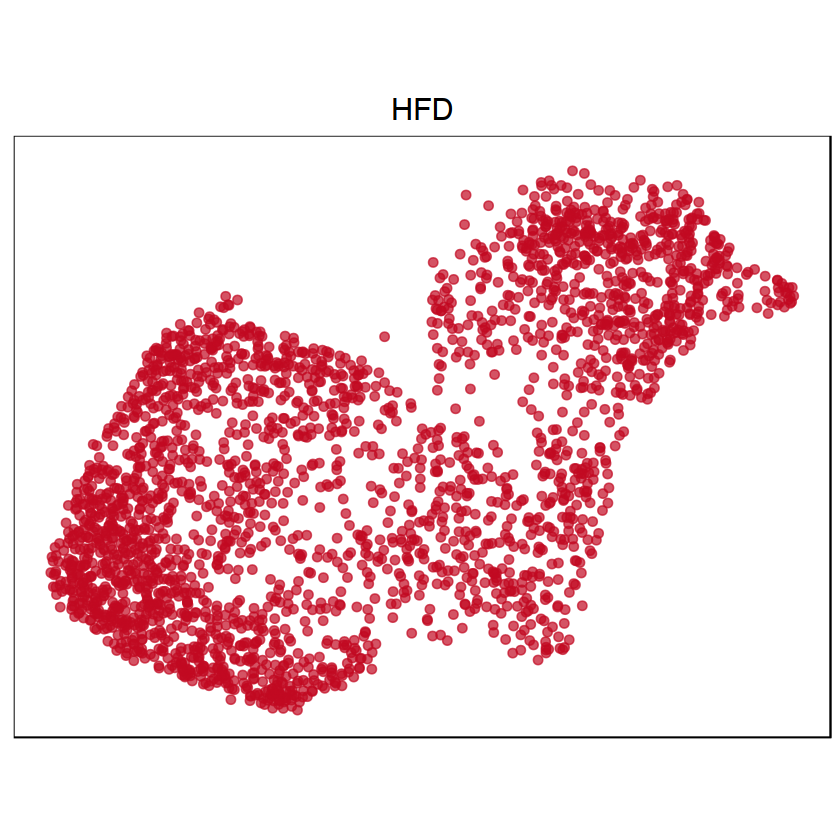

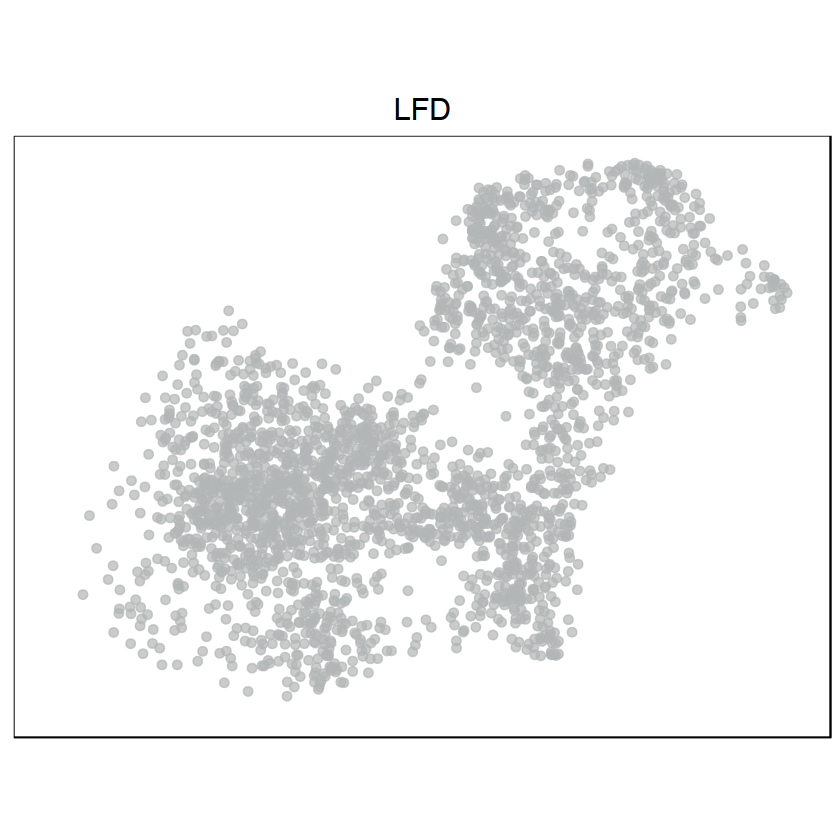

In [96]:
# Get cell metadata
cell_col_data <- getCellColData(proj)

# Identify clusters to remove
clusters_to_remove <- c("C1", "C2", "C3", "C4")

# Get cells to keep (those NOT in clusters 1-4)
cells_to_keep <- rownames(cell_col_data)[!cell_col_data$Clusters %in% clusters_to_remove]

# Subset the project (using a simpler approach)
proj_filtered <- proj[cells_to_keep, ]

# Recalculate LSI on the filtered dataset
proj_filtered <- addIterativeLSI(
  ArchRProj = proj_filtered,
  useMatrix = "TileMatrix",
  name = "IterativeLSI",
  iterations = 2,
  force = TRUE
)

# Recalculate clusters
proj_filtered <- addClusters(
  input = proj_filtered,
  method = "Seurat",
  name = "Clusters",
  force = TRUE
)

# Recalculate UMAP
proj_filtered <- addUMAP(
  ArchRProj = proj_filtered,
  force = TRUE
)

# Extract UMAP coordinates and metadata
umap_df <- getEmbedding(ArchRProj = proj_filtered, embedding = "UMAP", returnDF = TRUE)
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_1"] <- "UMAP1"
colnames(umap_df)[colnames(umap_df) == "IterativeLSI#UMAP_Dimension_2"] <- "UMAP2"

cell_col_data_filtered <- getCellColData(proj_filtered)
umap_df$Clusters <- cell_col_data_filtered$Clusters
umap_df$Sample <- cell_col_data_filtered$Sample

# Get cluster colors using ArchR's palette
unique_clusters <- sort(unique(umap_df$Clusters))
cluster_colors <- paletteDiscrete(values = unique_clusters, set = "stallion")
names(cluster_colors) <- unique_clusters

# Get consistent axis limits for all plots
x_range <- range(umap_df$UMAP1)
y_range <- range(umap_df$UMAP2)

# Set consistent dot size and alpha (matching panel A-E)
dot_size <- 2
dot_alpha <- 0.7

# Common theme elements (matching panel A-E)
common_theme <- theme_minimal() +
  theme(
    panel.grid = element_blank(),
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    plot.title = element_text(hjust = 0.5, size = 18, face = "bold"),
    panel.background = element_rect(fill = "white"),
    panel.border = element_blank(),
    axis.line = element_blank()
  )

# Plot 1: All clusters on UMAP
p1 <- ggplot(umap_df, aes(x = UMAP1, y = UMAP2, color = Clusters)) +
  geom_point(size = dot_size, alpha = dot_alpha) +
  scale_color_manual(values = cluster_colors) +
  common_theme +
  labs(title = "UMAP (Clusters 1-4 Removed)") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range) +
  guides(color = guide_legend(override.aes = list(size = 3)))

# Plot 2: HFD only (dark red)
umap_df_hfd <- umap_df[umap_df$Sample == "HFD", ]

p2 <- ggplot(umap_df_hfd, aes(x = UMAP1, y = UMAP2)) +
  geom_point(color = "#c20922", size = dot_size, alpha = dot_alpha) +
  common_theme +
  labs(title = "HFD") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range)

# Plot 3: LFD only (light gray)
umap_df_lfd <- umap_df[umap_df$Sample == "LFD", ]

p3 <- ggplot(umap_df_lfd, aes(x = UMAP1, y = UMAP2)) +
  geom_point(color = "#b3b6b6", size = dot_size, alpha = dot_alpha) +
  common_theme +
  labs(title = "LFD") +
  coord_fixed(ratio = 1, xlim = x_range, ylim = y_range)

# Display plots
p1
p2
p3

# Save plots as SVG
ggsave("filtered_umap_all_clusters.svg", p1, width = 10, height = 8, dpi = 300)
ggsave("filtered_umap_hfd.svg", p2, width = 10, height = 8, dpi = 300)
ggsave("filtered_umap_lfd.svg", p3, width = 10, height = 8, dpi = 300)

Figure 4j

In [232]:
# Count cells per cluster
table(umap_df$Clusters)

# Or as a data frame
cluster_counts <- as.data.frame(table(umap_df$Clusters))
colnames(cluster_counts) <- c("Cluster", "nCells")
cluster_counts

# Also by sample
table(umap_df$Clusters, umap_df$Sample)

# Or as a nicer data frame with both
cluster_sample_counts <- as.data.frame(table(umap_df$Clusters, umap_df$Sample))
colnames(cluster_sample_counts) <- c("Cluster", "Sample", "nCells")
cluster_sample_counts


  C1  C10   C2   C3   C4   C5   C6   C7   C8   C9 
  62 1041  736  591  104  476  562  369  656  519 

Cluster,nCells
<fct>,<int>
C1,62
C10,1041
C2,736
C3,591
C4,104
C5,476
C6,562
C7,369
C8,656


     
      HFD LFD
  C1   34  28
  C10 269 772
  C2  379 357
  C3  284 307
  C4   47  57
  C5  290 186
  C6  238 324
  C7  148 221
  C8  602  54
  C9  369 150

Cluster,Sample,nCells
<fct>,<fct>,<int>
C1,HFD,34
C10,HFD,269
C2,HFD,379
C3,HFD,284
C4,HFD,47
C5,HFD,290
C6,HFD,238
C7,HFD,148
C8,HFD,602


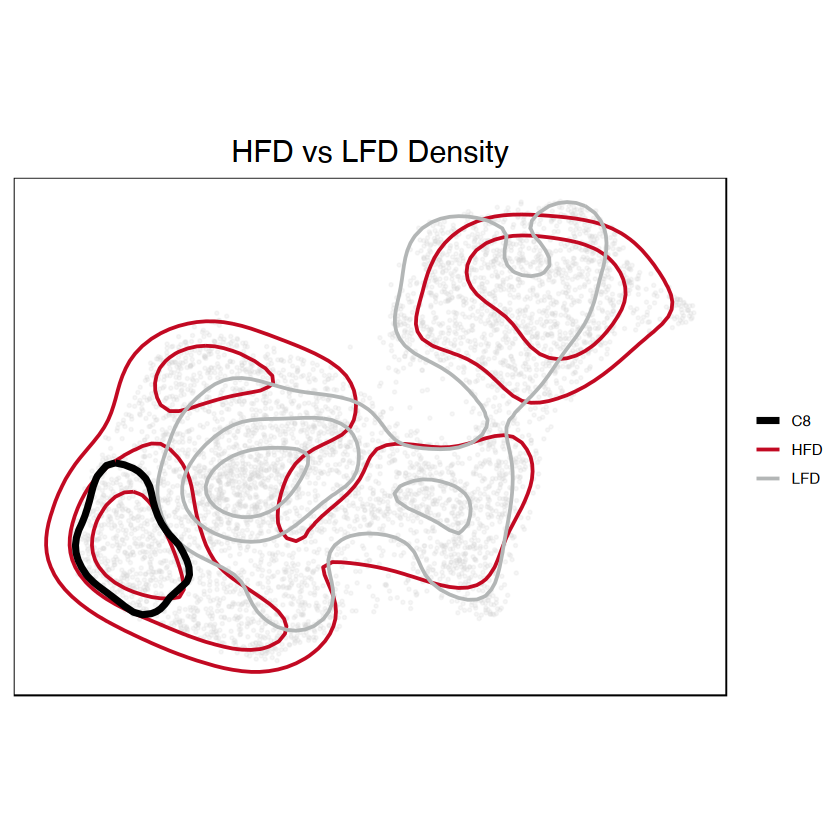

In [231]:
library(MASS)

# Compute density on expanded grid
x_lim <- c(min(umap_df$UMAP1) - 3, max(umap_df$UMAP1) + 3)
y_lim <- c(min(umap_df$UMAP2) - 3, max(umap_df$UMAP2) + 3)

# HFD density
kde_hfd <- kde2d(umap_df_hfd$UMAP1, umap_df_hfd$UMAP2, n = 100, lims = c(x_lim, y_lim))
kde_hfd_df <- data.frame(expand.grid(x = kde_hfd$x, y = kde_hfd$y), z = as.vector(kde_hfd$z))

# LFD density
kde_lfd <- kde2d(umap_df_lfd$UMAP1, umap_df_lfd$UMAP2, n = 100, lims = c(x_lim, y_lim))
kde_lfd_df <- data.frame(expand.grid(x = kde_lfd$x, y = kde_lfd$y), z = as.vector(kde_lfd$z))

# Cluster 8 density
umap_df_c8 <- umap_df[umap_df$Clusters == "C8", ]
kde_c8 <- kde2d(umap_df_c8$UMAP1, umap_df_c8$UMAP2, n = 100, lims = c(x_lim, y_lim))
kde_c8_df <- data.frame(expand.grid(x = kde_c8$x, y = kde_c8$y), z = as.vector(kde_c8$z))

p4_contour <- ggplot(umap_df, aes(x = UMAP1, y = UMAP2)) +
  geom_point(color = "lightgrey", size = 0.5, alpha = 0.2) +
  geom_contour(data = kde_hfd_df, aes(x = x, y = y, z = z, color = "HFD"), linewidth = 0.8, bins = 4) +
  geom_contour(data = kde_lfd_df, aes(x = x, y = y, z = z, color = "LFD"), linewidth = 0.8, bins = 4) +
  geom_contour(data = kde_c8_df, aes(x = x, y = y, z = z, color = "C8"), 
               linewidth = 1.5, bins = 2, linetype = "solid") +
  scale_color_manual(values = c("HFD" = "#c20922", "LFD" = "#b3b6b6", "C8" = "black"), name = "") +
  common_theme +
  labs(title = "HFD vs LFD Density") +
  coord_fixed(ratio = 1) +
  theme(legend.position = "right")

p4_contour

ggsave("densities.svg", p4_contour, width = 10, height = 8, dpi = 300)

Extended Figure 10a

In [247]:
figureGenes <- c("Klf2", "Cd69", "Itgae", "Runx3", "Hlf", "Bhlhe40", "Rbpj")

ArchR logging to : ArchRLogs/ArchR-plotEmbedding-75f6148a18c6-Date-2026-01-20_Time-11-31-21.355533.log
If there is an issue, please report to github with logFile!

Getting UMAP Embedding

ColorBy = GeneScoreMatrix

Getting Matrix Values...

2026-01-20 11:31:21.80273 : 



Plotting Embedding

1 
2 
3 
4 
5 
6 
7 


ArchR logging successful to : ArchRLogs/ArchR-plotEmbedding-75f6148a18c6-Date-2026-01-20_Time-11-31-21.355533.log



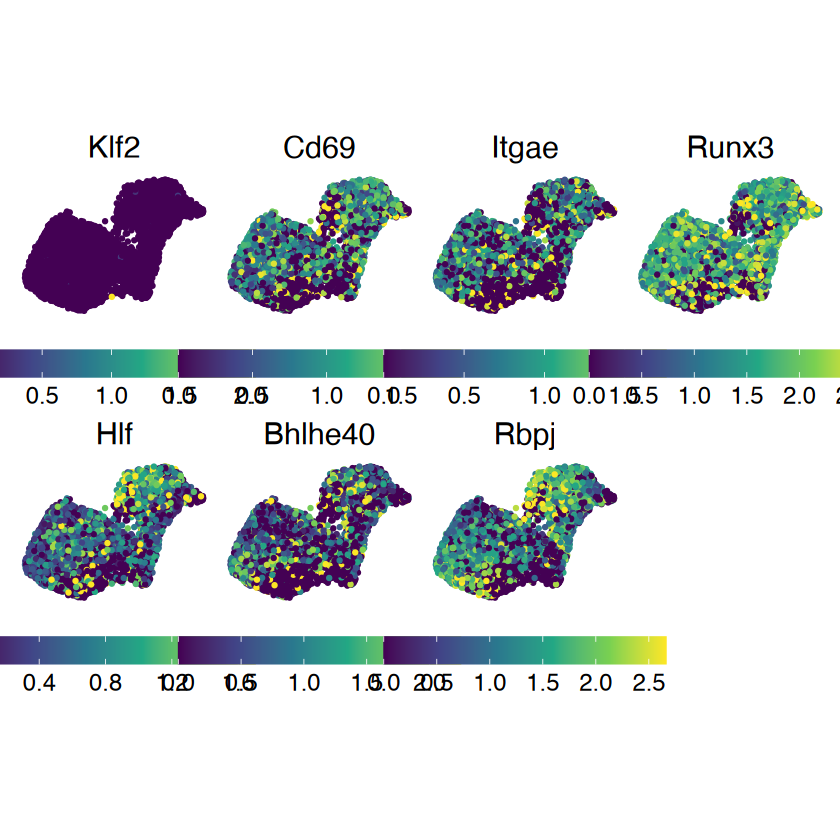

In [275]:
p_supplfigure <- plotEmbedding(
    ArchRProj = proj_filtered,
    colorBy = "GeneScoreMatrix", 
    name = figureGenes, 
    embedding = "UMAP",
    quantCut = c(0.01, 0.95),
    imputeWeights = NULL,
    plotAs = "points",
    size = 0.75,  
    force = TRUE
)

# Completely rebuild plots from extracted data
p2 <- lapply(seq_along(p_supplfigure), function(i) {
    # Extract the data from the ArchR plot
    original_plot <- p_supplfigure[[i]]
    plot_data <- original_plot$data
    gene_name <- names(p_supplfigure)[i]
    
    # Get the column name for the gene score (usually the 3rd column)
    color_col <- colnames(plot_data)[3]
    
    # Rebuild plot from scratch with ggplot2
    p <- ggplot(plot_data, aes_string(x = colnames(plot_data)[1], 
                                       y = colnames(plot_data)[2], 
                                       color = color_col)) +
        geom_point(size = 0.75) +  # NOW THIS WILL WORK - change this value
        scale_color_viridis_c(name = "") +
        theme_minimal() +
        theme(
            plot.margin = unit(c(0.05, 0.05, 0.05, 0.05), "cm"),
            axis.text.x = element_blank(), 
            axis.ticks.x = element_blank(), 
            axis.text.y = element_blank(), 
            axis.ticks.y = element_blank(),
            axis.title = element_blank(),
            plot.title = element_text(size = 18, hjust = 0.5),
            legend.key.size = unit(0.6, "cm"),          # Increased from 0.3
            legend.key.height = unit(0.6, "cm"),        # Added for more control
            legend.key.width = unit(1.2, "cm"),         # Added for wider color bar
            legend.text = element_text(size = 14),      # Increased from 10
            legend.title = element_blank(),  
            legend.position = "bottom",
            panel.grid = element_blank()
        ) +
        ggtitle(gene_name) +
        coord_fixed(ratio = 1)
    
    return(p)
})

# Create the grid
combined_plot <- wrap_plots(p2[1:length(p2)], ncol = 4)

# Display
print(combined_plot)

# Save as SVG
ggsave("plots/heatmap_suppl_15.svg", combined_plot, 
       width = 15, height = 20, 
       units = "in")

## Genome browser tracks of genes of interest, C8 vs. all

Fugyre 4k, Extended Data Figure 10b, c

In [ ]:
proj$C8_vs_Others <- ifelse(proj$Clusters == "C8", "C8", "Others")

# Calculate DARs comparing C8 vs all other clusters
DARs_C8_vs_All <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "PeakMatrix",
  groupBy = "C8_vs_Others",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  testMethod = "wilcoxon",
  useGroups = "C8",
  bgdGroups = "Others"
)

# Define genes of interest
genes_of_interest <- c("Rorc", "Cxcr6", "Tcf7", "Ikzf2", "Il1r1", 
                       "Il10", "Il7r", "Runx3", "Irf4", "Il2")

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-75f61ec509f3-Date-2026-01-13_Time-06-04-11.197109.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Integer.Matrix

2026-01-13 06:04:11.31911 : Matching Known Biases, 0.001 mins elapsed.

2026-01-13 06:04:11.796177 : Computing Pairwise Tests (1 of 1), 0.009 mins elapsed.

Pairwise Test C8 : Seqnames chr1

Pairwise Test C8 : Seqnames chr10

Pairwise Test C8 : Seqnames chr11

Pairwise Test C8 : Seqnames chr12

Pairwise Test C8 : Seqnames chr13

Pairwise Test C8 : Seqnames chr14

Pairwise Test C8 : Seqnames chr15

Pairwise Test C8 : Seqnames chr16

Pairwise Test C8 : Seqnames chr17

Pairwise Test C8 : Seqnames chr18

Pairwise Test C8 : Seqnames chr19

Pairwise Test C8 : Seqnames chr2

Pairwise Test C8 : Seqnames chr3

Pairwise Test C8 : Seqnames chr4

Pairwise Test C8 : Seqnames chr5

Pairwise Test C8 : Seqnames chr6

Pairwise Test C8 : Seqnames chr7

Pairwise Test C8 : Seqnames chr8

Pairwise Test C8

GRanges object with 1 range and 2 metadata columns:
      seqnames            ranges strand |     gene_id      symbol
         <Rle>         <IRanges>  <Rle> | <character> <character>
  [1]     chr3 94372794-94398276      + |       19885        Rorc
  -------
  seqinfo: 21 sequences from mm10 genome


2026-01-13 06:04:30.410934 : Adding Bulk Tracks (1 of 1), 0.001 mins elapsed.

2026-01-13 06:04:30.9476 : Adding Feature Tracks (1 of 1), 0.01 mins elapsed.

2026-01-13 06:04:30.990056 : Adding Gene Tracks (1 of 1), 0.011 mins elapsed.

2026-01-13 06:04:31.119545 : Plotting, 0.013 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-plotBrowserTrack-75f61a10404d-Date-2026-01-13_Time-06-04-30.343632.log



[1] "Added to PDF: Rorc"
trerror: Interrupted system call


ArchR logging to : ArchRLogs/ArchR-plotBrowserTrack-75f66db6d3ec-Date-2026-01-13_Time-06-04-31.534163.log
If there is an issue, please report to github with logFile!

2026-01-13 06:04:31.589193 : Validating Region, 0.001 mins elapsed.



...

 metadata columns:
      seqnames            ranges strand |     gene_id      symbol
         <Rle>         <IRanges>  <Rle> | <character> <character>
  [1]     chr3 37120713-37125954      - |       16183         Il2
  -------
  seqinfo: 21 sequences from mm10 genome


2026-01-13 06:04:40.74992 : Adding Bulk Tracks (1 of 1), 0.001 mins elapsed.

2026-01-13 06:04:41.458421 : Adding Feature Tracks (1 of 1), 0.013 mins elapsed.

2026-01-13 06:04:41.513893 : Adding Gene Tracks (1 of 1), 0.014 mins elapsed.

2026-01-13 06:04:41.663771 : Plotting, 0.017 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-plotBrowserTrack-75f667561392-Date-2026-01-13_Time-06-04-40.668576.log



[1] "Added to PDF: Il2"
strerror: Interrupted system call


agg_record_1357805042 
                    2

lots/browser_tracks_C8_vs_All_genes.pdf"
[1] "Number of significant DARs (C8 enriched vs All): "


In [327]:
plot_gene_browser <- function(proj, gene_symbol, DARs_object, upstream = 20000, downstream = 110000) {
    
    # Get gene annotation
    genes <- getGeneAnnotation(proj)$genes
    gene_info <- genes[which(genes$symbol == gene_symbol)]
    
    # Create region (gene +/- buffer for peak finding)
    gene_chr <- as.character(seqnames(gene_info))
    gene_start <- start(gene_info)
    gene_end <- end(gene_info)
    
    region <- GRanges(seqnames = gene_chr, 
                      ranges = IRanges(start = gene_start - 200000, 
                                       end = gene_end + 200000))
    
    # Get peaks in region
    allPeaks <- getPeakSet(proj)
    region_peaks <- subsetByOverlaps(allPeaks, region)
    
    # Get transcripts for alternative TSS
    library(TxDb.Mmusculus.UCSC.mm10.knownGene)
    txdb <- TxDb.Mmusculus.UCSC.mm10.knownGene
    region_transcripts <- subsetByOverlaps(transcripts(txdb), region)
    all_tss <- resize(region_transcripts, width = 1, fix = "start")
    
    # Main TSS and promoter
    main_tss <- resize(gene_info, width = 1, fix = "start")
    main_tss_visible <- resize(main_tss, width = 500, fix = "center")
    main_promoter <- promoters(gene_info, upstream = 1000, downstream = 100)
    promoter_peaks <- subsetByOverlaps(region_peaks, main_promoter)
    
    # Alternative promoters
    alt_tss <- all_tss[start(all_tss) != start(main_tss)]
    alt_promoters <- promoters(alt_tss, upstream = 1000, downstream = 100)
    alt_promoter_peaks <- subsetByOverlaps(region_peaks, alt_promoters)
    
    # Intragenic
    intragenic <- subsetByOverlaps(region_peaks, gene_info)
    intragenic <- intragenic[!names(intragenic) %in% c(names(promoter_peaks), names(alt_promoter_peaks))]
    
    # Distal (<200kb)
    tss_200kb <- resize(main_tss, width = 400000, fix = "center")
    distal <- subsetByOverlaps(region_peaks, tss_200kb)
    distal <- distal[!names(distal) %in% names(subsetByOverlaps(region_peaks, gene_info))]
    distal <- distal[!names(distal) %in% names(promoter_peaks)]
    
    # DARs
    markerPeaks_C8 <- getMarkers(DARs_object, cutOff = "FDR <= 0.05 & Log2FC >= 1")
    dars_c8 <- region_peaks[names(region_peaks) %in% rownames(markerPeaks_C8)]
    
    markerPeaks_Others <- getMarkers(DARs_object, cutOff = "FDR <= 0.05 & Log2FC <= -1")
    dars_others <- region_peaks[names(region_peaks) %in% rownames(markerPeaks_Others)]
    
    # Scale bars - position near start of view
    scale_start <- gene_start - (upstream - 5000)
    scale_10kb <- GRanges(seqnames = gene_chr, ranges = IRanges(start = scale_start, width = 10000))
    scale_20kb <- GRanges(seqnames = gene_chr, ranges = IRanges(start = scale_start + 15000, width = 20000))
    
    # Feature list
    featuresList <- GRangesList(
        "10kb" = scale_10kb,
        "20kb" = scale_20kb,
        "TSS" = main_tss_visible,
        "Main_Promoter" = main_promoter,
        "Alt_Promoters" = alt_promoters,
        "Intragenic" = intragenic,
        "Distal_<200kb" = distal,
        "DARs_C8" = dars_c8,
        "DARs_Others" = dars_others
    )
    featuresList <- featuresList[lengths(featuresList) > 0]
    
    # Combine regions for highlight
    highlight_regions <- c(main_promoter, all_tss, alt_promoters, intragenic, distal)
    
    # Filter gene annotation
    geneAnno_filtered <- getGeneAnnotation(proj)
    geneAnno_filtered$genes <- geneAnno_filtered$genes[which(geneAnno_filtered$genes$symbol == gene_symbol)]
    
    # Plot
    p <- plotBrowserTrack(
        ArchRProj = proj, 
        groupBy = "C8_vs_Others", 
        geneSymbol = gene_symbol,
        features = featuresList,
        upstream = upstream,
        downstream = downstream,
        tileSize = 400,
        minCells = 25,
        highlight = highlight_regions,
        highlightFill = "firebrick3",
        title = paste0(gene_symbol, " - C8 vs All"),
        geneAnnotation = geneAnno_filtered
    )
    
    return(p)
}


ArchR logging to : ArchRLogs/ArchR-plotBrowserTrack-75f6d9ea0ef-Date-2026-01-20_Time-12-11-03.531068.log
If there is an issue, please report to github with logFile!

2026-01-20 12:11:03.703377 : Validating Region, 0.003 mins elapsed.



GRanges object with 1 range and 2 metadata columns:
      seqnames              ranges strand |     gene_id      symbol
         <Rle>           <IRanges>  <Rle> | <character> <character>
  [1]    chr13 112464070-112506860      + |       16195       Il6st
  -------
  seqinfo: 21 sequences from mm10 genome


2026-01-20 12:11:03.750947 : Adding Bulk Tracks (1 of 1), 0.004 mins elapsed.



R_zmq_msg_send errno: 4 strerror: Interrupted system call


2026-01-20 12:11:06.168603 : Adding Feature Tracks (1 of 1), 0.044 mins elapsed.

2026-01-20 12:11:07.27147 : Adding Gene Tracks (1 of 1), 0.062 mins elapsed.

2026-01-20 12:11:08.495033 : Plotting, 0.083 mins elapsed.

ArchR logging successful to : ArchRLogs/ArchR-plotBrowserTrack-75f6d9ea0ef-Date-2026-01-20_Time-12-11-03.531068.log



agg_record_740574080 
                   2

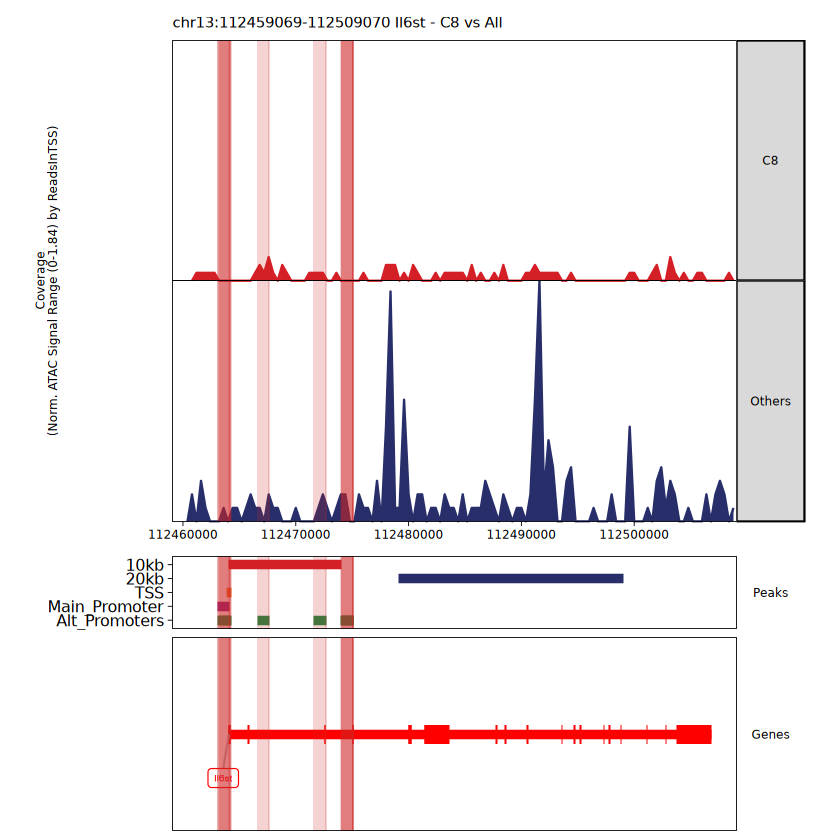

In [328]:
p <- plot_gene_browser(proj, "Il6st", DARs_C8_vs_all, upstream = 5000, downstream = 45000)

# Display in notebook
grid::grid.newpage()
grid::grid.draw(p[["Il6st"]])

# Then save
svg("Il6st_browser.svg", width = 8, height = 4)
grid::grid.newpage()
grid::grid.draw(p[["Il6st"]])
dev.off()

In [192]:
# Get differential gene scores for C8 vs all
geneScores_C8_vs_All <- getMarkerFeatures(
  ArchRProj = proj,
  useMatrix = "GeneScoreMatrix",
  groupBy = "C8_vs_Others",
  testMethod = "wilcoxon",
  bias = c("TSSEnrichment", "log10(nFrags)"),
  useGroups = "C8",
  bgdGroups = "Others"
)

# Get significant genes
markerGenes_C8 <- getMarkers(geneScores_C8_vs_All, cutOff = "FDR <= 0.05 & Log2FC >= 1")

# View top genes
head(markerGenes_C8, 20)

# Save
write.csv(as.data.frame(markerGenes_C8), "Genes_C8_vs_All_enriched.csv", row.names = TRUE)

# Also get genes depleted in C8
markerGenes_Others <- getMarkers(geneScores_C8_vs_All, cutOff = "FDR <= 0.05 & Log2FC <= -1")
write.csv(as.data.frame(markerGenes_Others), "Genes_C8_vs_All_depleted.csv", row.names = TRUE)

ArchR logging to : ArchRLogs/ArchR-getMarkerFeatures-75f6492e72f1-Date-2026-01-17_Time-13-43-15.725358.log
If there is an issue, please report to github with logFile!

MatrixClass = Sparse.Double.Matrix

2026-01-17 13:43:15.854558 : Matching Known Biases, 0.001 mins elapsed.

2026-01-17 13:43:16.337101 : Computing Pairwise Tests (1 of 1), 0.009 mins elapsed.

Pairwise Test C8 : Seqnames chr1

Pairwise Test C8 : Seqnames chr10

Pairwise Test C8 : Seqnames chr11

Pairwise Test C8 : Seqnames chr12

Pairwise Test C8 : Seqnames chr13

Pairwise Test C8 : Seqnames chr14

Pairwise Test C8 : Seqnames chr15

Pairwise Test C8 : Seqnames chr16

Pairwise Test C8 : Seqnames chr17

Pairwise Test C8 : Seqnames chr18

Pairwise Test C8 : Seqnames chr19

Pairwise Test C8 : Seqnames chr2

Pairwise Test C8 : Seqnames chr3

Pairwise Test C8 : Seqnames chr4

Pairwise Test C8 : Seqnames chr5

Pairwise Test C8 : Seqnames chr6

Pairwise Test C8 : Seqnames chr7

Pairwise Test C8 : Seqnames chr8

Pairwise Test C8

List of length 1
names(1): C8